<a href="https://colab.research.google.com/github/ananyasharma213/Ai-and-Society-Assignment/blob/main/Assignment_(AI_and_society).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT**

In [ ]:

import random
import numpy as np
import pandas as pd

SEED = 820
random.seed(SEED)
np.random.seed(SEED)

print("Seed set to:", SEED)


Seed set to: 820


In [ ]:

url = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"
df = pd.read_csv(url)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (7214, 53)

First 5 rows:


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0



Column names:
['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob', 'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number', 'c_offense_date', 'c_arrest_date', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number', 'r_charge_degree', 'r_days_from_arrest', 'r_offense_date', 'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid', 'is_violent_recid', 'vr_case_number', 'vr_charge_degree', 'vr_offense_date', 'vr_charge_desc', 'type_of_assessment', 'decile_score.1', 'score_text', 'screening_date', 'v_type_of_assessment', 'v_decile_score', 'v_score_text', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end', 'event', 'two_year_recid']

Duplicate rows: 0


In [ ]:

print("Missing values in each column:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nData types:")
display(df.dtypes)

target_cols = [
    col for col in ["is_recid", "two_year_recid", "decile_score"]
    if col in df.columns
]

print("\nImportant columns:")
display(df[target_cols].head())


Missing values in each column:


,0
violent_recid,7214
vr_charge_degree,6395
vr_offense_date,6395
vr_case_number,6395
vr_charge_desc,6395
c_arrest_date,6077
r_jail_in,4898
r_days_from_arrest,4898
r_jail_out,4898
r_charge_desc,3801



Data types:


,0
id,int64
name,object
first,object
last,object
compas_screening_date,object
sex,object
dob,object
age,int64
age_cat,object
race,object



Important columns:


,is_recid,two_year_recid,decile_score
0,0,0,1
1,1,1,3
2,1,1,4
3,0,0,8
4,0,0,1


### Data Preprocessing

**Missing Values:** Missing values were inspected before modelling. The target variable and predictor columns were checked, and the handling of missing observations was performed before fitting the models.

**Categorical Encoding:** Categorical predictors, including race, sex, and charge degree, were encoded numerically using one-hot encoding where required.

**Feature Scaling:** Numerical features such as age and priors count were standardised where required by the modelling pipeline.

**Outlier Handling:** Outliers were not automatically removed without investigation, because extreme prior-offence counts may represent genuine observations. The analysis should document any outlier treatment actually performed in the code.

**Reproducibility:** The train-test split uses a fixed random seed so that model evaluation can be reproduced.

**Model A: Linear Regression**

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

SEED = 820

# Model A target
target_A = "decile_score"

features_A = [
    "age",
    "priors_count",
    "race",
    "sex",
    "c_charge_degree"
]

data_A = df[features_A + [target_A]].copy()
data_A = data_A.dropna(subset=[target_A])

X_A = data_A[features_A]
y_A = data_A[target_A]

numeric_features_A = ["age", "priors_count"]
categorical_features_A = ["race", "sex", "c_charge_degree"]

preprocessor_A = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features_A),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features_A)
])

X_A_train, X_A_test, y_A_train, y_A_test = train_test_split(
    X_A, y_A,
    test_size=0.30,
    random_state=SEED
)

model_A = Pipeline([
    ("preprocessor", preprocessor_A),
    ("regressor", LinearRegression())
])

model_A.fit(X_A_train, y_A_train)

pred_A = model_A.predict(X_A_test)

print("Model A: Linear Regression")
print("MAE:", round(mean_absolute_error(y_A_test, pred_A), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_A_test, pred_A)), 3))
print("R²:", round(r2_score(y_A_test, pred_A), 3))


Model A: Linear Regression
MAE: 1.759
RMSE: 2.172
R²: 0.417


**Model B: Logistic Regression**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

target_B = "two_year_recid"

features_B = [
    "age",
    "priors_count",
    "race",
    "sex",
    "c_charge_degree"
]

data_B = df[features_B + [target_B]].copy()
data_B = data_B.dropna(subset=[target_B])

X_B = data_B[features_B]
y_B = data_B[target_B].astype(int)

numeric_features_B = ["age", "priors_count"]
categorical_features_B = ["race", "sex", "c_charge_degree"]

preprocessor_B = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features_B),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features_B)
])

X_B_train, X_B_test, y_B_train, y_B_test = train_test_split(
    X_B, y_B,
    test_size=0.30,
    random_state=SEED,
    stratify=y_B
)

model_B = Pipeline([
    ("preprocessor", preprocessor_B),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_B.fit(X_B_train, y_B_train)

prob_B = model_B.predict_proba(X_B_test)[:, 1]
pred_B = (prob_B >= 0.5).astype(int)

print("Model B: Logistic Regression")
print("Accuracy:", round(accuracy_score(y_B_test, pred_B), 3))
print("Precision:", round(precision_score(y_B_test, pred_B, zero_division=0), 3))
print("Recall:", round(recall_score(y_B_test, pred_B, zero_division=0), 3))
print("F1-score:", round(f1_score(y_B_test, pred_B, zero_division=0), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_B_test, pred_B))

Model B: Logistic Regression
Accuracy: 0.67
Precision: 0.663
Recall: 0.545
F1-score: 0.598

Confusion matrix:
[[919 270]
 [444 532]]


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

# Keep rows where both target values are available
common_data = df[
    ["decile_score", "two_year_recid",
     "age", "priors_count", "race", "sex", "c_charge_degree"]
].dropna(subset=["decile_score", "two_year_recid"]).copy()

# Use the same row indices for both models
train_idx, test_idx = train_test_split(
    common_data.index,
    test_size=0.30,
    random_state=SEED,
    stratify=common_data["two_year_recid"]
)

# Model A: predict decile_score
XA_train = common_data.loc[train_idx, features_A]
yA_train = common_data.loc[train_idx, "decile_score"]
XA_test = common_data.loc[test_idx, features_A]
yA_test = common_data.loc[test_idx, "decile_score"]

# Model B: predict two_year_recid
XB_train = common_data.loc[train_idx, features_B]
yB_train = common_data.loc[train_idx, "two_year_recid"].astype(int)
XB_test = common_data.loc[test_idx, features_B]
yB_test = common_data.loc[test_idx, "two_year_recid"].astype(int)

# Refit both pipelines
model_A_shared = clone(model_A)
model_B_shared = clone(model_B)

model_A_shared.fit(XA_train, yA_train)
model_B_shared.fit(XB_train, yB_train)

# Predictions on the same test rows
pred_A_shared = model_A_shared.predict(XA_test)
prob_B_shared = model_B_shared.predict_proba(XB_test)[:, 1]
pred_B_shared = (prob_B_shared >= 0.5).astype(int)

# Convert Model A's continuous predictions into high/low risk
median_A = np.median(pred_A_shared)
pred_A_high = (pred_A_shared >= median_A).astype(int)

# Compare the two binary predictions
comparison_matrix = confusion_matrix(
    pred_A_high, pred_B_shared, labels=[0, 1]
)

mismatches = int(np.sum(pred_A_high != pred_B_shared))
total = len(pred_A_shared)

print("Shared test rows:", total)
print("Model A median prediction:", round(median_A, 3))
print("\nAgreement matrix (rows=Model A, columns=Model B):")
print(comparison_matrix)
print("\nMismatches:", mismatches)
print("Mismatch percentage:", round(100 * mismatches / total, 2), "%")
print("Agreement percentage:", round(100 * (total - mismatches) / total, 2), "%")

Shared test rows: 2165
Model A median prediction: 4.607

Agreement matrix (rows=Model A, columns=Model B):
[[1063   19]
 [ 300  783]]

Mismatches: 319
Mismatch percentage: 14.73 %
Agreement percentage: 85.27 %


### Q1. Linear Threshold vs Logistic Threshold

The two models were evaluated on the same test set of 2,165 observations. Model A, Linear Regression, predicted a continuous `decile_score`, with a median predicted score of 4.607. Its Mean Absolute Error (MAE) was 1.759, Root Mean Squared Error (RMSE) was 2.172, and R² was 0.417. Model B, Logistic Regression, predicted the binary outcome `two_year_recid`. It achieved an accuracy of 0.670, precision of 0.663, recall of 0.545, and F1-score of 0.598.

To compare the models, Model A's predictions were divided into low- and high-risk categories using its median predicted score, while Model B used a probability threshold of 0.50. The agreement matrix showed that 1,063 observations were classified as low risk by both models, while 783 were classified as high risk by both. However, 19 observations were classified as low risk by Model A but high risk by Model B, and 300 were classified as high risk by Model A but low risk by Model B.

Overall, the models disagreed on 319 of the 2,165 observations, representing 14.73% of the test set. Their agreement percentage was 85.27%. These results indicate substantial overall agreement, but the disagreements remain important because risk classifications can influence consequential decisions.

The disagreement is not necessarily evidence that either model is incorrect. The models predict different outcomes: Model A estimates a recidivism-related decile score, whereas Model B predicts a binary two-year recidivism outcome. Their thresholds also differ. Therefore, agreement measures consistency between their classifications, not predictive correctness or fairness. Actual performance must be assessed against appropriate outcomes, and subgroup error rates should also be examined before considering either model for consequential use.

In [ ]:
# Cell 9: Explore demographic groups

print("Race group counts:")
display(df["race"].value_counts(dropna=False))

print("\nRecidivism rate by race:")
race_rates = df.groupby("race")["two_year_recid"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

race_rates = race_rates.rename(
    columns={"count": "Number of people", "mean": "Recidivism rate"}
)

display(race_rates.round(3))

print("\nRecidivism rate by sex:")
sex_rates = df.groupby("sex")["two_year_recid"].agg(
    ["count", "mean"]
).rename(
    columns={"count": "Number of people", "mean": "Recidivism rate"}
)

display(sex_rates.round(3))

Race group counts:


,count
race,
African-American,3696
Caucasian,2454
Hispanic,637
Other,377
Asian,32
Native American,18



Recidivism rate by race:


,Number of people,Recidivism rate
race,,
Native American,18,0.556
African-American,3696,0.514
Caucasian,2454,0.394
Hispanic,637,0.364
Other,377,0.353
Asian,32,0.281



Recidivism rate by sex:


,Number of people,Recidivism rate
sex,,
Female,1395,0.357
Male,5819,0.473


In [ ]:
# Fairness metrics across thresholds (African-American vs Caucasian)
# Ratios are symmetric: min(group rates) / max(group rates), so 1.0 means parity.
# Equalized Odds requires BOTH TPR and FPR parity. We report both component ratios
# and a clearly labelled conservative summary (the smaller of the two ratios).

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

fairness_test = common_data.loc[test_idx, ["race", "two_year_recid"]].copy()
fairness_test["actual"] = fairness_test["two_year_recid"].astype(int).to_numpy()
fairness_test["probability"] = np.asarray(prob_B_shared)

group_A = "African-American"
group_B = "Caucasian"

def get_group_metrics(group_df, threshold):
    actual = group_df["actual"].to_numpy()
    predicted = (group_df["probability"].to_numpy() >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {
        "Positive rate": predicted.mean(),
        "TPR": tp / (tp + fn) if (tp + fn) else np.nan,
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "PPV": tp / (tp + fp) if (tp + fp) else np.nan
    }

def parity_ratio(a, b):
    # Symmetric ratio: avoids treating A/B and B/A differently.
    if pd.isna(a) or pd.isna(b) or max(a, b) == 0:
        return np.nan
    return min(a, b) / max(a, b)

results = []
for threshold in np.round(np.arange(0.05, 1.00, 0.10), 2):
    A = get_group_metrics(fairness_test[fairness_test["race"] == group_A], threshold)
    B = get_group_metrics(fairness_test[fairness_test["race"] == group_B], threshold)
    tpr_ratio = parity_ratio(A["TPR"], B["TPR"])
    fpr_ratio = parity_ratio(A["FPR"], B["FPR"])
    results.append({
        "Threshold": threshold,
        "DP ratio": parity_ratio(A["Positive rate"], B["Positive rate"]),
        "TPR ratio": tpr_ratio,
        "FPR ratio": fpr_ratio,
        "EO summary ratio (min TPR/FPR parity)": min(tpr_ratio, fpr_ratio) if pd.notna(tpr_ratio) and pd.notna(fpr_ratio) else np.nan,
        "PP ratio": parity_ratio(A["PPV"], B["PPV"]),
        "TPR difference (AA-Caucasian)": A["TPR"] - B["TPR"] if pd.notna(A["TPR"]) and pd.notna(B["TPR"]) else np.nan,
        "FPR difference (AA-Caucasian)": A["FPR"] - B["FPR"] if pd.notna(A["FPR"]) and pd.notna(B["FPR"]) else np.nan,
        "TPR African-American": A["TPR"], "TPR Caucasian": B["TPR"],
        "FPR African-American": A["FPR"], "FPR Caucasian": B["FPR"]
    })

fairness_table = pd.DataFrame(results)
# Backward-compatible column for existing plots/tables. This is a summary, not a
# standalone standard definition of Equalized Odds; always inspect TPR and FPR ratios too.
fairness_table["EO ratio"] = fairness_table["EO summary ratio (min TPR/FPR parity)"]
print("Fairness metrics by threshold (symmetric parity ratios; 1.0 is ideal)")
display(fairness_table.round(3))


Fairness metrics by threshold (symmetric parity ratios; 1.0 is ideal)


,Threshold,DP ratio,TPR ratio,FPR ratio,EO summary ratio (min TPR/FPR parity),PP ratio,TPR difference (AA-Caucasian),FPR difference (AA-Caucasian),TPR African-American,TPR Caucasian,FPR African-American,FPR Caucasian,EO ratio
0,0.05,1.000,1.000,1.000,1.000,0.764,0.000,0.000,1.000,1.000,1.000,1.000,1.000
1,0.15,0.940,0.984,0.915,0.915,0.800,0.016,0.082,0.993,0.977,0.968,0.886,0.915
2,0.25,0.830,0.935,0.771,0.771,0.861,0.062,0.203,0.962,0.900,0.885,0.682,0.771
3,0.35,0.735,0.836,0.690,0.690,0.870,0.148,0.222,0.905,0.757,0.716,0.495,0.690
4,0.45,0.579,0.687,0.538,0.538,0.906,0.245,0.225,0.781,0.537,0.488,0.262,0.538
5,0.55,0.445,0.589,0.345,0.345,0.988,0.209,0.139,0.509,0.300,0.212,0.073,0.345
6,0.65,0.375,0.519,0.253,0.253,0.945,0.148,0.089,0.308,0.160,0.119,0.030,0.253
7,0.75,0.328,0.456,0.203,0.203,0.942,0.099,0.042,0.183,0.083,0.053,0.011,0.203
8,0.85,0.333,0.487,0.000,0.000,0.894,0.039,0.009,0.075,0.037,0.009,0.000,0.000
9,0.95,0.609,0.717,0.000,0.000,0.571,-0.003,0.006,0.007,0.010,0.006,0.000,0.000


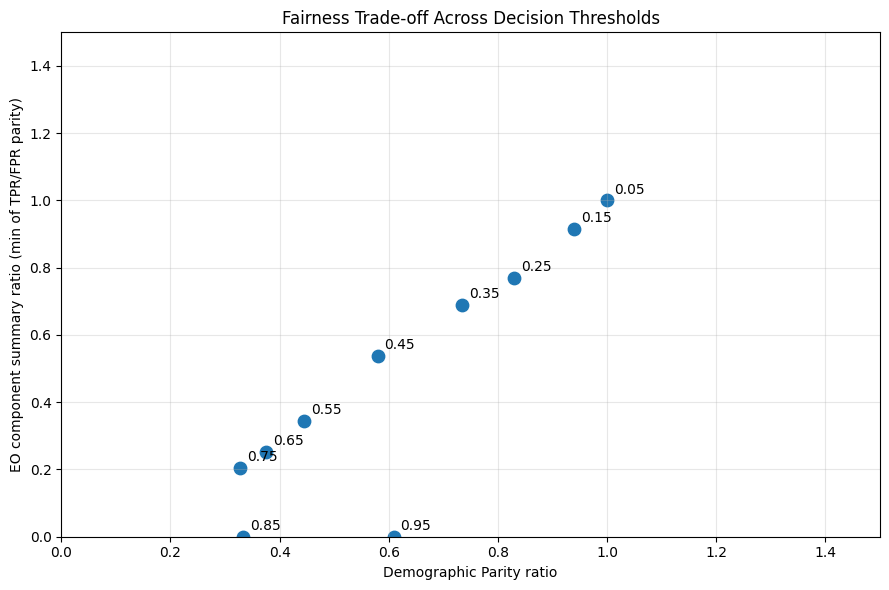

In [ ]:
# Fairness trade-off scatter plot: DP vs conservative EO-component summary
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
plt.scatter(fairness_table["DP ratio"], fairness_table["EO ratio"], s=80)
for _, row in fairness_table.iterrows():
    if pd.notna(row["DP ratio"]) and pd.notna(row["EO ratio"]):
        plt.annotate(f'{row["Threshold"]:.2f}', (row["DP ratio"], row["EO ratio"]),
                     xytext=(5, 5), textcoords="offset points")
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio")
plt.ylabel("EO component summary ratio (min of TPR/FPR parity)")
plt.title("Fairness Trade-off Across Decision Thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


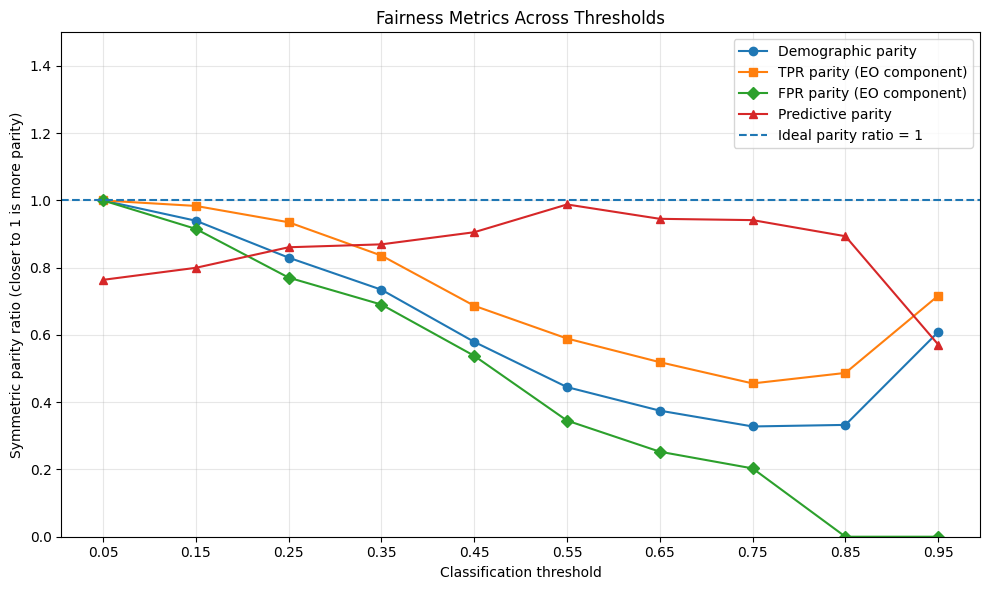

In [ ]:
import matplotlib.pyplot as plt

# Plot the two components of Equalized Odds separately, plus DP and PP.
plt.figure(figsize=(10, 6))
for column, label, marker in [
    ("DP ratio", "Demographic parity", "o"),
    ("TPR ratio", "TPR parity (EO component)", "s"),
    ("FPR ratio", "FPR parity (EO component)", "D"),
    ("PP ratio", "Predictive parity", "^")
]:
    plt.plot(fairness_table["Threshold"], fairness_table[column], marker=marker, label=label)
plt.axhline(y=1.0, linestyle="--", label="Ideal parity ratio = 1")
plt.xlabel("Classification threshold")
plt.ylabel("Symmetric parity ratio (closer to 1 is more parity)")
plt.title("Fairness Metrics Across Thresholds")
plt.xticks(fairness_table["Threshold"])
plt.ylim(0, 1.5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**2.1- Simpson’s Paradox Hunt**

In [ ]:

# Part 2.1 — Simpson's Paradox Hunt
import pandas as pd
import statsmodels.api as sm

# Use the same outcome and predictors for all three models
simpson_data = df[
    ["two_year_recid", "priors_count", "age", "race"]
].dropna().copy()

simpson_data["two_year_recid"] = simpson_data["two_year_recid"].astype(int)

# Fit logistic regression and extract coefficients, confidence intervals,
# and p-values for the same predictors in each group
def fit_logistic(data, group_name):
    X = sm.add_constant(
        data[["priors_count", "age"]].astype(float)
    )
    y = data["two_year_recid"]

    model = sm.Logit(y, X).fit(disp=False)

    ci = model.conf_int()

    results = []
    for predictor in ["priors_count", "age"]:
        results.append({
            "Group": group_name,
            "N": len(data),
            "Predictor": predictor,
            "Coefficient": model.params[predictor],
            "CI Lower": ci.loc[predictor, 0],
            "CI Upper": ci.loc[predictor, 1],
            "p-value": model.pvalues[predictor]
        })

    return model, results


# Model 1: Full dataset
full_model, results_full = fit_logistic(
    simpson_data, "Full dataset"
)

# Model 2: African-American subgroup
aa_data = simpson_data[
    simpson_data["race"] == "African-American"
]
aa_model, results_aa = fit_logistic(
    aa_data, "African-American"
)

# Model 3: Caucasian subgroup
cauc_data = simpson_data[
    simpson_data["race"] == "Caucasian"
]
cauc_model, results_cauc = fit_logistic(
    cauc_data, "Caucasian"
)

# Combine results for comparison
simpson_results = pd.DataFrame(
    results_full + results_aa + results_cauc
)

print("SIMPSON'S PARADOX — LOGISTIC REGRESSION COMPARISON")

print("Total rows:", len(simpson_data))
print("Groups:", simpson_data["race"].value_counts().to_dict())
print("Models fitted: Full dataset, African-American, Caucasian")

display(simpson_results.round(4))

print("\nSample sizes:")
print("Full dataset:", len(simpson_data))
print("African-American:", len(aa_data))
print("Caucasian:", len(cauc_data))


SIMPSON'S PARADOX — LOGISTIC REGRESSION COMPARISON
Total rows: 7214
Groups: {'African-American': 3696, 'Caucasian': 2454, 'Hispanic': 637, 'Other': 377, 'Asian': 32, 'Native American': 18}
Models fitted: Full dataset, African-American, Caucasian


,Group,N,Predictor,Coefficient,CI Lower,CI Upper,p-value
0,Full dataset,7214,priors_count,0.1604,0.1472,0.1735,0.0
1,Full dataset,7214,age,-0.0478,-0.0525,-0.0430,0.0
2,African-American,3696,priors_count,0.1485,0.1319,0.1651,0.0
3,African-American,3696,age,-0.0554,-0.0628,-0.0480,0.0
4,Caucasian,2454,priors_count,0.1845,0.1565,0.2124,0.0
5,Caucasian,2454,age,-0.0380,-0.0453,-0.0307,0.0



Sample sizes:
Full dataset: 7214
African-American: 3696
Caucasian: 2454


**2.2 — Omitted Variable Bias (OVB) karenge**

In [ ]:

# Cell 13: Omitted Variable Bias (OVB)

import statsmodels.api as sm
import pandas as pd
import numpy as np

ovb_data = df[
    ["two_year_recid", "priors_count", "age", "race", "sex"]
].dropna().copy()

ovb_data["two_year_recid"] = ovb_data["two_year_recid"].astype(int)

# Encode categorical variables
ovb_data = pd.get_dummies(
    ovb_data,
    columns=["race", "sex"],
    drop_first=True,
    dtype=int
)

# Full model includes prior criminal history
predictors_full = [
    col for col in ovb_data.columns
    if col != "two_year_recid"
]

# Reduced model omits priors_count
predictors_reduced = [
    col for col in predictors_full
    if col != "priors_count"
]

X_full = sm.add_constant(
    ovb_data[predictors_full].astype(float)
)

X_reduced = sm.add_constant(
    ovb_data[predictors_reduced].astype(float)
)

y = ovb_data["two_year_recid"]

full_ovb_model = sm.Logit(y, X_full).fit(disp=False)
reduced_ovb_model = sm.Logit(y, X_reduced).fit(disp=False)

# Compare coefficients for predictors present in both models
common_predictors = [
    col for col in predictors_reduced
    if col != "const"
]

ovb_results = pd.DataFrame({
    "Full coefficient": full_ovb_model.params[common_predictors],
    "Reduced coefficient": reduced_ovb_model.params[common_predictors]
})

ovb_results["Absolute change"] = (
    ovb_results["Reduced coefficient"]
    - ovb_results["Full coefficient"]
)

ovb_results["Percentage change (%)"] = np.where(
    ovb_results["Full coefficient"].abs() > 1e-10,
    100 * ovb_results["Absolute change"]
    / full_ovb_model.params[common_predictors].abs(),
    np.nan
)

print("Full model predictors:", predictors_full)
print("Reduced model predictors:", predictors_reduced)
print("\nCoefficient comparison:")
display(ovb_results.round(4))

print("\nFull model sample size:", int(full_ovb_model.nobs))
print("Reduced model sample size:", int(reduced_ovb_model.nobs))


Full model predictors: ['priors_count', 'age', 'race_Asian', 'race_Caucasian', 'race_Hispanic', 'race_Native American', 'race_Other', 'sex_Male']
Reduced model predictors: ['age', 'race_Asian', 'race_Caucasian', 'race_Hispanic', 'race_Native American', 'race_Other', 'sex_Male']

Coefficient comparison:


,Full coefficient,Reduced coefficient,Absolute change,Percentage change (%)
age,-0.0470,-0.0319,0.0151,32.1605
race_Asian,-0.4798,-0.9305,-0.4506,-93.9154
race_Caucasian,-0.0452,-0.3263,-0.2811,-622.1046
race_Hispanic,-0.2554,-0.5596,-0.3042,-119.0782
race_Native American,0.0203,0.2010,0.1807,891.2223
race_Other,-0.2586,-0.6163,-0.3577,-138.3094
sex_Male,0.3190,0.4883,0.1693,53.0640



Full model sample size: 7214
Reduced model sample size: 7214


In [ ]:
# Cell 14: Find confident wrong predictions

# Join fairness_test with additional demographic features from common_data using indices
adversarial = fairness_test.copy()
adversarial[["age", "priors_count", "sex"]] = common_data.loc[test_idx, ["age", "priors_count", "sex"]]

adversarial["predicted"] = (
    adversarial["probability"] >= 0.5
).astype(int)

adversarial["correct"] = (
    adversarial["predicted"] == adversarial["actual"]
)

# Confidently wrong cases
high_confidence_wrong = adversarial[
    (
        (adversarial["probability"] >= 0.75)
        & (adversarial["actual"] == 0)
    )
    |
    (
        (adversarial["probability"] <= 0.25)
        & (adversarial["actual"] == 1)
    )
].copy()

print("Total test rows:", len(adversarial))
print("Confidently wrong cases:", len(high_confidence_wrong))
print(
    "Percentage of test set:",
    round(100 * len(high_confidence_wrong) / len(adversarial), 2),
    "%"
)

print("\nRace distribution: adversarial cases")
display(
    high_confidence_wrong["race"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage (%)")
)

print("\nRace distribution: full test set")
display(
    adversarial["race"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage (%)")
)

print("\nFirst 10 confidently wrong cases:")
display(
    high_confidence_wrong[
        ["race", "actual", "probability", "predicted"]
    ].head(10)
)



# Additional demographic and feature comparison

print("FULL TEST SET — numeric feature averages")
display(
    adversarial[["age", "priors_count"]
].mean().round(2).rename("Mean").to_frame())

print("\nHIGH-CONFIDENCE WRONG CASES — numeric feature averages")
display(
    high_confidence_wrong[["age", "priors_count"]
].mean().round(2).rename("Mean").to_frame())

print("\nSex distribution: full test set (%)")
display(
    adversarial["sex"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage (%)")
)

print("\nSex distribution: confidently wrong cases (%)")
display(
    high_confidence_wrong["sex"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage (%)")
)

Total test rows: 2165
Confidently wrong cases: 105
Percentage of test set: 4.85 %

Race distribution: adversarial cases


,Percentage (%)
race,
African-American,46.67
Caucasian,33.33
Hispanic,16.19
Other,2.86
Asian,0.95



Race distribution: full test set


,Percentage (%)
race,
African-American,50.21
Caucasian,35.33
Hispanic,8.73
Other,4.90
Asian,0.51
Native American,0.32



First 10 confidently wrong cases:


...

,Mean
age,46.21
priors_count,5.50



Sex distribution: full test set (%)


,Percentage (%)
sex,
Male,80.09
Female,19.91



Sex distribution: confidently wrong cases (%)


,Percentage (%)
sex,
Male,80.95
Female,19.05


In [ ]:
# Cell 15: Reproducible sample of 50 adversarial cases

adversarial_sample = high_confidence_wrong.sample(
    n=min(50, len(high_confidence_wrong)),
    random_state=820
).copy()

print("Selected adversarial cases:", len(adversarial_sample))

print("\nRace distribution in selected sample:")
display(
    adversarial_sample["race"]
    .value_counts()
    .rename("Count")
    .to_frame()
)

print("\nSelected sample as percentages:")
display(
    adversarial_sample["race"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage (%)")
    .to_frame()
)

print("\nSample preview:")
display(
    adversarial_sample[
        ["race", "actual", "probability", "predicted"]
    ].head(10)
)


# Common characteristic analysis for the selected sample

print("Sample size:", len(adversarial_sample))

print("\nNumeric feature averages — selected sample")
display(
    adversarial_sample[["age", "priors_count"]]
    .mean()
    .round(2)
    .rename("Mean")
    .to_frame()
)

# Check prior counts >= 5
if "priors_count" in adversarial_sample.columns:
    high_priors_pct = (
        adversarial_sample["priors_count"].ge(5).mean() * 100
    )
    print(
        f"Sample with priors_count >= 5: "
        f"{high_priors_pct:.2f}% "
        f"({adversarial_sample['priors_count'].ge(5).sum()} "
        f"of {len(adversarial_sample)})"
    )

# Sex distribution in the sample
if "sex" in adversarial_sample.columns:
    print("\nSex distribution in selected sample (%)")
    display(
        adversarial_sample["sex"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .rename("Percentage (%)")
    )


Selected adversarial cases: 50

Race distribution in selected sample:


,Count
race,
Caucasian,20
African-American,19
Hispanic,9
Other,2



Selected sample as percentages:


,Percentage (%)
race,
Caucasian,40.0
African-American,38.0
Hispanic,18.0
Other,4.0



Sample preview:


,race,actual,probability,predicted
2048,African-American,0,0.884873,1
900,Hispanic,1,0.169540,0
3440,Caucasian,1,0.228344,0
2520,African-American,1,0.168112,0
4764,African-American,0,0.979172,1
571,African-American,0,0.828056,1
3564,Caucasian,1,0.249563,0
1126,African-American,1,0.160020,0
1551,Hispanic,1,0.200923,0
5262,Caucasian,1,0.204173,0


Sample size: 50

Numeric feature averages — selected sample


,Mean
age,47.46
priors_count,5.42


Sample with priors_count >= 5: 30.00% (15 of 50)

Sex distribution in selected sample (%)


,Percentage (%)
sex,
Male,78.0
Female,22.0


In [ ]:
# Cell 16: Accuracy and group rates at each threshold

accuracy_results = []

for threshold in np.round(np.arange(0.05, 1.00, 0.10), 2):
    actual = fairness_test["actual"].to_numpy()
    probability = fairness_test["probability"].to_numpy()
    predicted = (probability >= threshold).astype(int)

    accuracy = (predicted == actual).mean()

    accuracy_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy
    })

accuracy_table = pd.DataFrame(accuracy_results)

# Combine accuracy with fairness metrics
final_fairness_table = fairness_table.merge(
    accuracy_table,
    on="Threshold"
)

display(final_fairness_table.round(3))

,Threshold,DP ratio,TPR ratio,FPR ratio,EO summary ratio (min TPR/FPR parity),PP ratio,TPR difference (AA-Caucasian),FPR difference (AA-Caucasian),TPR African-American,TPR Caucasian,FPR African-American,FPR Caucasian,EO ratio,Accuracy
0,0.05,1.000,1.000,1.000,1.000,0.764,0.000,0.000,1.000,1.000,1.000,1.000,1.000,0.452
1,0.15,0.940,0.984,0.915,0.915,0.800,0.016,0.082,0.993,0.977,0.968,0.886,0.915,0.487
2,0.25,0.830,0.935,0.771,0.771,0.861,0.062,0.203,0.962,0.900,0.885,0.682,0.771,0.545
3,0.35,0.735,0.836,0.690,0.690,0.870,0.148,0.222,0.905,0.757,0.716,0.495,0.690,0.609
4,0.45,0.579,0.687,0.538,0.538,0.906,0.245,0.225,0.781,0.537,0.488,0.262,0.538,0.654
5,0.55,0.445,0.589,0.345,0.345,0.988,0.209,0.139,0.509,0.300,0.212,0.073,0.345,0.655
6,0.65,0.375,0.519,0.253,0.253,0.945,0.148,0.089,0.308,0.160,0.119,0.030,0.253,0.617
7,0.75,0.328,0.456,0.203,0.203,0.942,0.099,0.042,0.183,0.083,0.053,0.011,0.203,0.594
8,0.85,0.333,0.487,0.000,0.000,0.894,0.039,0.009,0.075,0.037,0.009,0.000,0.000,0.572
9,0.95,0.609,0.717,0.000,0.000,0.571,-0.003,0.006,0.007,0.010,0.006,0.000,0.000,0.552


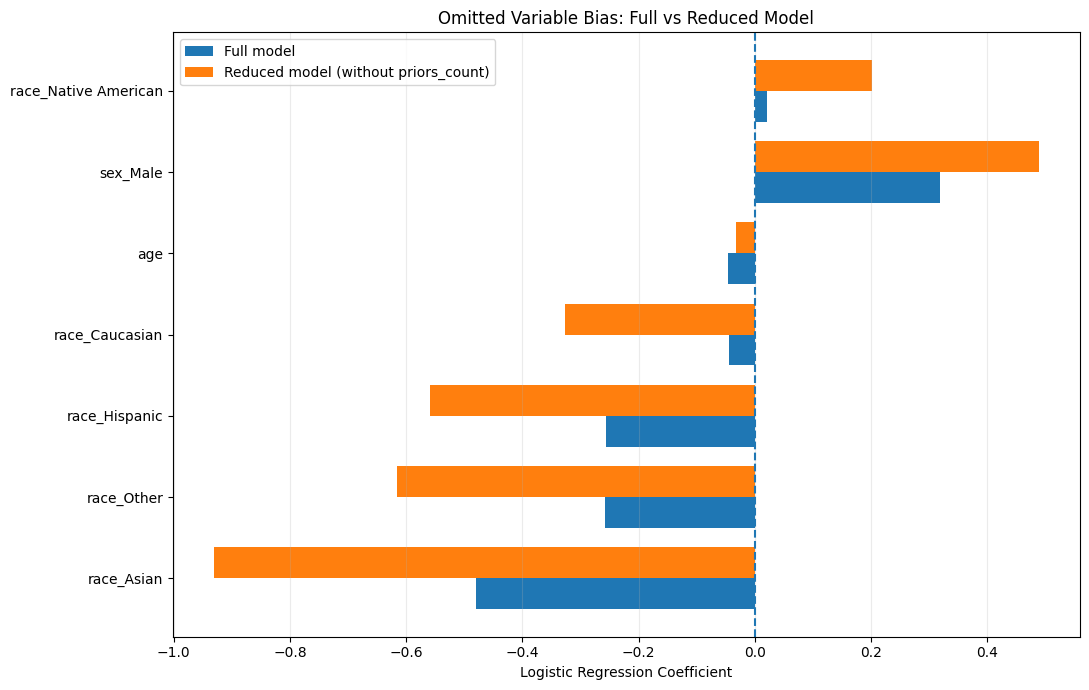

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Compare coefficients from the full and reduced models
plot_data = ovb_results.drop(
    index="priors_count", errors="ignore"
).dropna(subset=["Full coefficient", "Reduced coefficient"])

plot_data = plot_data.sort_values(
    "Absolute change", ascending=True
)

y_pos = np.arange(len(plot_data))
height = 0.38

plt.figure(figsize=(11, 7))

plt.barh(
    y_pos - height / 2,
    plot_data["Full coefficient"],
    height,
    label="Full model"
)

plt.barh(
    y_pos + height / 2,
    plot_data["Reduced coefficient"],
    height,
    label="Reduced model (without priors_count)"
)

plt.yticks(y_pos, plot_data.index)
plt.axvline(0, linestyle="--")
plt.xlabel("Logistic Regression Coefficient")
plt.title("Omitted Variable Bias: Full vs Reduced Model")
plt.legend()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

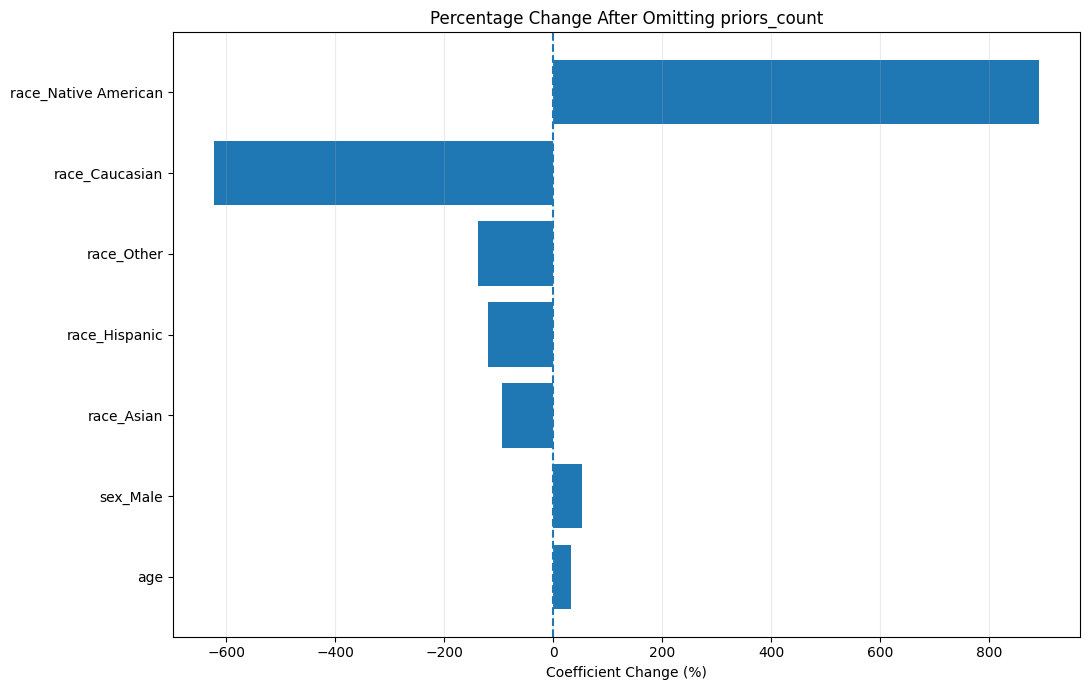

In [ ]:
change_data = ovb_results.drop(
    index="priors_count", errors="ignore"
).dropna(subset=["Percentage change (%)"])

change_data = change_data.sort_values(
    "Percentage change (%)",
    key=lambda s: s.abs()
)

plt.figure(figsize=(11, 7))

plt.barh(
    change_data.index,
    change_data["Percentage change (%)"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Coefficient Change (%)")
plt.title("Percentage Change After Omitting priors_count")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

Full test rows: 2165
Adversarial sample rows: 50
FULL TEST SET — numeric feature averages


,Mean
age,34.87
priors_count,3.43



ADVERSARIAL SAMPLE OF 50 — numeric feature averages


,Mean
age,47.46
priors_count,5.42



Full test set — sex distribution (%)


,Percentage
sex,
Male,80.09
Female,19.91



Adversarial sample — sex distribution (%)


,Percentage
sex,
Male,78.0
Female,22.0


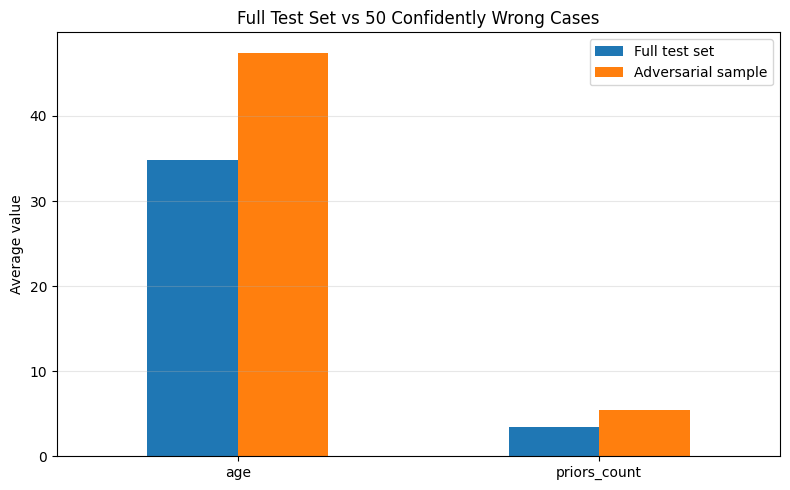

In [ ]:
# Cell 20: Compare adversarial sample with full test set

# Get demographics and prior-offense features for the same test rows
test_details = df.loc[
    test_idx,
    ["age", "sex", "priors_count", "race"]
].copy()

test_details["probability"] = prob_B_shared
test_details["actual"] = yB_test.to_numpy()

# Match the 50 selected adversarial cases by their original row index
sample_details = test_details.loc[
    adversarial_sample.index
].copy()

print("Full test rows:", len(test_details))
print("Adversarial sample rows:", len(sample_details))

assert len(test_details) == len(test_idx)
assert len(sample_details) == len(adversarial_sample)
print("FULL TEST SET — numeric feature averages")
display(
    test_details[["age", "priors_count"]]
    .mean()
    .round(2)
    .to_frame("Mean")
)

print("\nADVERSARIAL SAMPLE OF 50 — numeric feature averages")
display(
    sample_details[["age", "priors_count"]]
    .mean()
    .round(2)
    .to_frame("Mean")
)

print("\nFull test set — sex distribution (%)")
display(
    (test_details["sex"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

print("\nAdversarial sample — sex distribution (%)")
display(
    (sample_details["sex"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

# Visual comparison of average age and priors_count
import matplotlib.pyplot as plt
import numpy as np

comparison = pd.DataFrame({
    "Full test set": test_details[["age", "priors_count"]].mean(),
    "Adversarial sample": sample_details[["age", "priors_count"]].mean()
})

comparison.plot(kind="bar", figsize=(8, 5))
plt.ylabel("Average value")
plt.title("Full Test Set vs 50 Confidently Wrong Cases")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

import statsmodels.api as sm
import pandas as pd

simpson_check = df[
    ["two_year_recid", "priors_count", "age", "race"]
].dropna().copy()

simpson_check = simpson_check[
    simpson_check["race"].isin(
        ["African-American", "Caucasian", "Hispanic", "Other"]
    )
]

results = []

for group in [
    "All selected groups",
    "African-American",
    "Caucasian",
    "Hispanic",
    "Other"
]:
    if group == "All selected groups":
        sub = simpson_check
    else:
        sub = simpson_check[simpson_check["race"] == group]

    if sub["two_year_recid"].nunique() < 2:
        print(f"Skipping {group}: only one outcome class")
        continue

    X = sm.add_constant(
        sub[["priors_count", "age"]].astype(float)
    )
    y = sub["two_year_recid"].astype(int)

    model = sm.Logit(y, X).fit(disp=False)
    ci = model.conf_int().loc["priors_count"]

    # IMPORTANT: append is INSIDE the loop
    results.append({
        "Group": group,
        "N": len(sub),
        "Priors coefficient": model.params["priors_count"],
        "95% CI lower": ci.iloc[0],
        "95% CI upper": ci.iloc[1],
        "p-value": model.pvalues["priors_count"]
    })

    print(f"Finished model: {group}")

# These lines must be OUTSIDE the loop
simpson_check_table = pd.DataFrame(results)

print("Number of results:", len(results))
display(simpson_check_table.round(4))


Finished model: All selected groups
Finished model: African-American
Finished model: Caucasian
Finished model: Hispanic
Finished model: Other
Number of results: 5


,Group,N,Priors coefficient,95% CI lower,95% CI upper,p-value
0,All selected groups,7164,0.1597,0.1465,0.1728,0.0
1,African-American,3696,0.1485,0.1319,0.1651,0.0
2,Caucasian,2454,0.1845,0.1565,0.2124,0.0
3,Hispanic,637,0.1454,0.0938,0.1970,0.0
4,Other,377,0.3016,0.2003,0.4030,0.0


In [ ]:

# Cell 22: Preprocessing Documentation

import pandas as pd
import numpy as np

# 1. Dataset overview
print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)

print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. Missing values
print("\n" + "=" * 60)
print("2. MISSING VALUES")
print("=" * 60)

required = [
    "decile_score",
    "two_year_recid",
    "age",
    "priors_count",
    "race",
    "sex",
    "c_charge_degree"
]

missing_summary = df[required].isnull().sum().to_frame(
    "Missing values"
)
missing_summary["Missing (%)"] = (
    missing_summary["Missing values"] / len(df) * 100
).round(2)

display(missing_summary)

print("\nTotal missing values in required columns:",
      int(df[required].isnull().sum().sum()))

# 3. Duplicate rows
print("\n" + "=" * 60)
print("3. DUPLICATE ROWS")
print("=" * 60)

print("Duplicate rows:", df.duplicated().sum())

# 4. Numeric feature summary
print("\n" + "=" * 60)
print("4. NUMERIC FEATURE SUMMARY")
print("=" * 60)

numeric_cols = ["age", "priors_count", "decile_score"]

display(df[numeric_cols].describe().round(2))

# 5. Categorical feature values
print("\n" + "=" * 60)
print("5. CATEGORICAL FEATURE DISTRIBUTIONS")
print("=" * 60)

categorical_cols = ["race", "sex", "c_charge_degree"]

for col in categorical_cols:
    print(f"\n{col} — category counts:")
    display(
        df[col]
        .value_counts(dropna=False)
        .to_frame("Count")
    )

# 6. Check for possible outliers using the IQR method
print("\n" + "=" * 60)
print("6. NUMERIC OUTLIER CHECK (IQR METHOD)")
print("=" * 60)

outlier_results = []

for col in numeric_cols:
    values = df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (values < lower_bound) | (values > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Potential outliers": int(outlier_count),
        "Outlier (%)": outlier_count / len(values) * 100
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table.round(2))

# 7. Document encoding and scaling
print("\n" + "=" * 60)
print("7. PREPROCESSING METHODS")
print("=" * 60)

print("Categorical encoding:")
print("- pd.get_dummies() with drop_first=True is used in the")
print("  relevant statistical model cells.")

print("\nScaling:")
print("- Check the model pipelines for any scaler.")
print("- No scaling is performed by this documentation cell.")

print("\nMissing values:")
print("- Missingness is reported above.")
print("- Model-specific cells may use dropna() or other handling.")

print("\nOutliers:")
print("- IQR-based potential outliers are counted above.")
print("- This cell identifies potential outliers; it does not remove them.")

print("\nDocumentation complete.")


1. DATASET OVERVIEW
Dataset shape: (7214, 53)
Number of rows: 7214
Number of columns: 53

2. MISSING VALUES


,Missing values,Missing (%)
decile_score,0,0.0
two_year_recid,0,0.0
age,0,0.0
priors_count,0,0.0
race,0,0.0
sex,0,0.0
c_charge_degree,0,0.0



Total missing values in required columns: 0

3. DUPLICATE ROWS
Duplicate rows: 0

4. NUMERIC FEATURE SUMMARY


,age,priors_count,decile_score
count,7214.00,7214.00,7214.00
mean,34.82,3.47,4.51
std,11.89,4.88,2.86
min,18.00,0.00,1.00
25%,25.00,0.00,2.00
50%,31.00,2.00,4.00
75%,42.00,5.00,7.00
max,96.00,38.00,10.00



5. CATEGORICAL FEATURE DISTRIBUTIONS

race — category counts:


...


c_charge_degree — category counts:


,Count
c_charge_degree,
F,4666
M,2548



6. NUMERIC OUTLIER CHECK (IQR METHOD)


,Feature,Q1,Q3,IQR,Lower bound,Upper bound,Potential outliers,Outlier (%)
0,age,25.0,42.0,17.0,-0.5,67.5,61,0.85
1,priors_count,0.0,5.0,5.0,-7.5,12.5,455,6.31
2,decile_score,2.0,7.0,5.0,-5.5,14.5,0,0.00



7. PREPROCESSING METHODS
Categorical encoding:
- pd.get_dummies() with drop_first=True is used in the
  relevant statistical model cells.

Scaling:
- Check the model pipelines for any scaler.
- No scaling is performed by this documentation cell.

Missing values:
- Missingness is reported above.
- Model-specific cells may use dropna() or other handling.

Outliers:
- IQR-based potential outliers are counted above.
- This cell identifies potential outliers; it does not remove them.

Documentation complete.


In [ ]:

# Cell 24: Compare Model A and Model B on the Same Test Set

import numpy as np
from sklearn.metrics import confusion_matrix

# Model A: Linear Regression predicts decile_score
# Use the median of actual training target scores as the threshold
median_A = np.median(pred_A_shared)

# Convert Model A predictions into binary risk predictions
# 1 = High risk, 0 = Low risk
pred_A_high = (pred_A_shared >= median_A).astype(int)

# Model B: Logistic Regression predicts recidivism probability
# Use the assignment's 0.5 probability threshold
pred_B_high = (prob_B_shared >= 0.5).astype(int)

# Ensure both models have predictions for the same test cases
assert len(pred_A_high) == len(pred_B_high), \
    "Error: Model A and Model B have different test-set sizes."

# Compare Model A and Model B predictions
comparison_matrix = confusion_matrix(
    pred_A_high,
    pred_B_high,
    labels=[0, 1]
)

# Calculate agreement and disagreement
mismatches = np.sum(pred_A_high != pred_B_high)
total = len(pred_A_high)

mismatch_percentage = (mismatches / total * 100) if total > 0 else 0
agreement_percentage = (
    (total - mismatches) / total * 100
) if total > 0 else 0

# Display results
print("MODEL A vs MODEL B")
print("-" * 40)
print("Model A median threshold:", round(median_A, 3))
print("Model B probability threshold: 0.5")

print("\nConfusion Matrix:")
print("Rows = Model A predictions [Low risk, High risk]")
print("Columns = Model B predictions [Low risk, High risk]")
print(comparison_matrix)

print("\nTotal test cases:", total)
print("Mismatches:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")
print("Agreement percentage:", round(agreement_percentage, 2), "%")


MODEL A vs MODEL B
----------------------------------------
Model A median threshold: 4.607
Model B probability threshold: 0.5

Confusion Matrix:
Rows = Model A predictions [Low risk, High risk]
Columns = Model B predictions [Low risk, High risk]
[[1063   19]
 [ 300  783]]

Total test cases: 2165
Mismatches: 319
Mismatch percentage: 14.73 %
Agreement percentage: 85.27 %


In [ ]:

# Display fairness results for all thresholds

required_columns = ["Threshold", "DP ratio", "EO ratio", "PP ratio"]

# Check that all required columns exist
missing_columns = [
    col for col in required_columns
    if col not in fairness_table.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    display(fairness_table[required_columns].round(4))

    print("\nTotal thresholds:", len(fairness_table))
    print("Missing EO values:", fairness_table["EO ratio"].isna().sum())
    print("Missing DP values:", fairness_table["DP ratio"].isna().sum())
    print("Missing PP values:", fairness_table["PP ratio"].isna().sum())


,Threshold,DP ratio,EO ratio,PP ratio
0,0.05,1.0000,1.0000,0.7639
1,0.15,0.9397,0.9154,0.7997
2,0.25,0.8299,0.7706,0.8608
3,0.35,0.7346,0.6904,0.8695
4,0.45,0.5794,0.5380,0.9055
5,0.55,0.4449,0.3454,0.9881
6,0.65,0.3749,0.2528,0.9454
7,0.75,0.3279,0.2031,0.9415
8,0.85,0.3326,0.0000,0.8936
9,0.95,0.6090,0.0000,0.5714



Total thresholds: 10
Missing EO values: 0
Missing DP values: 0
Missing PP values: 0


In [ ]:

# Full Dataset Logistic Regression
# Outcome: two_year_recid
# Predictors: priors_count and age

import statsmodels.api as sm
import pandas as pd

simpson_df = df[
    ["two_year_recid", "priors_count", "age"]
].dropna().copy()

X = sm.add_constant(
    simpson_df[["priors_count", "age"]].astype(float)
)
y = simpson_df["two_year_recid"].astype(int)

full_model = sm.Logit(y, X).fit(disp=False)

print("FULL DATASET LOGISTIC REGRESSION")
print("Number of rows:", int(full_model.nobs))

print(
    "\nCoefficient for priors_count:",
    round(full_model.params["priors_count"], 4)
)

print(
    "95% Confidence Interval:",
    full_model.conf_int()
    .loc["priors_count"]
    .round(4)
    .tolist()
)

print(
    "P-value:",
    f"{full_model.pvalues['priors_count']:.6g}"
)


FULL DATASET LOGISTIC REGRESSION
Number of rows: 7214

Coefficient for priors_count: 0.1604
95% Confidence Interval: [0.1472, 0.1735]
P-value: 3.13076e-126


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

# Identify numerical and categorical features present in the datasets
numeric_features = [
    "age",
    "priors_count"
]

categorical_features = [
    "sex",
    "race",
    "c_charge_degree"
]

# Preprocess numerical and categorical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Model A: Linear Regression
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_A_train, y_A_train)
reg_predictions = linear_model.predict(X_A_test)

print("MODEL A: LINEAR REGRESSION")
print("MAE:", round(mean_absolute_error(y_A_test, reg_predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_A_test, reg_predictions)), 4))
print("R2 Score:", round(r2_score(y_A_test, reg_predictions), 4))

# Model B: Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=SEED))
])

logistic_model.fit(X_B_train, y_B_train)
clf_predictions = logistic_model.predict(X_B_test)

print("\nMODEL B: LOGISTIC REGRESSION")
print("Accuracy:", round(accuracy_score(y_B_test, clf_predictions), 4))
print("Precision:", round(precision_score(y_B_test, clf_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_B_test, clf_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_B_test, clf_predictions, zero_division=0), 4))
print("\nClassification Report:")
print(classification_report(y_B_test, clf_predictions))

print("Confusion Matrix:")
print(confusion_matrix(y_B_test, clf_predictions))

tn, fp, fn, tp = confusion_matrix(y_B_test, clf_predictions).ravel()

print("False Positive Rate:", round(fp / (fp + tn), 4))
print("False Negative Rate:", round(fn / (fn + tp), 4))

MODEL A: LINEAR REGRESSION
MAE: 1.7591
RMSE: 2.172
R2 Score: 0.4169

MODEL B: LOGISTIC REGRESSION
Accuracy: 0.6702
Precision: 0.6633
Recall: 0.5451
F1 Score: 0.5984

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.77      0.72      1189
           1       0.66      0.55      0.60       976

    accuracy                           0.67      2165
   macro avg       0.67      0.66      0.66      2165
weighted avg       0.67      0.67      0.67      2165

Confusion Matrix:
[[919 270]
 [444 532]]
False Positive Rate: 0.2271
False Negative Rate: 0.4549


In [ ]:
from sklearn.metrics import accuracy_score, recall_score

# Keep test-set demographic groups aligned with predictions
fairness_df = df.loc[X_B_test.index, ["race", "sex"]].copy()

fairness_df["actual"] = y_B_test
fairness_df["predicted"] = clf_predictions

# Evaluate each racial group
race_results = []

for group, data in fairness_df.groupby("race"):
    actual_positive = (data["actual"] == 1).sum()
    predicted_positive = (data["predicted"] == 1).sum()

    race_results.append({
        "Race": group,
        "Test Records": len(data),
        "Actual Positive Rate": round(data["actual"].mean(), 3),
        "Predicted Positive Rate": round(data["predicted"].mean(), 3),
        "Accuracy": round(
            accuracy_score(data["actual"], data["predicted"]), 3
        ),
        "Recall": round(
            recall_score(data["actual"], data["predicted"],
                         zero_division=0), 3
        ),
        "Actual Positives": actual_positive,
        "Predicted Positives": predicted_positive
    })

race_results_df = pd.DataFrame(race_results)

display(race_results_df)

,Race,Test Records,Actual Positive Rate,Predicted Positive Rate,Accuracy,Recall,Actual Positives,Predicted Positives
0,African-American,1087,0.513,0.506,0.671,0.672,558,550
1,Asian,11,0.273,0.091,0.636,0.000,3,1
2,Caucasian,765,0.392,0.269,0.676,0.430,300,206
3,Hispanic,189,0.418,0.138,0.603,0.190,79,26
4,Native American,7,0.429,0.286,0.857,0.667,3,2
5,Other,106,0.311,0.160,0.736,0.333,33,17


In [ ]:

# Fairness stress test: remove race and sex from model inputs

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# These features are available in common_data
features_without_sensitive = [
    "age",
    "priors_count",
    "c_charge_degree"
]

X_train_reduced = common_data.loc[train_idx, features_without_sensitive].copy()
X_test_reduced = common_data.loc[test_idx, features_without_sensitive].copy()

y_train_reduced = common_data.loc[train_idx, "two_year_recid"].astype(int)
y_test_reduced = common_data.loc[test_idx, "two_year_recid"].astype(int)

reduced_numeric_features = ["age", "priors_count"]
reduced_categorical_features = ["c_charge_degree"]

reduced_preprocessor = ColumnTransformer(transformers=[
    ("num", clone(numeric_transformer), reduced_numeric_features),
    ("cat", clone(categorical_transformer), reduced_categorical_features)
])

reduced_model = Pipeline(steps=[
    ("preprocessor", reduced_preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=820))
])

reduced_model.fit(X_train_reduced, y_train_reduced)
reduced_predictions = reduced_model.predict(X_test_reduced)

print("MODEL WITHOUT RACE AND SEX")
print("Accuracy:", round(accuracy_score(y_test_reduced, reduced_predictions), 4))
print("Precision:", round(precision_score(y_test_reduced, reduced_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_reduced, reduced_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test_reduced, reduced_predictions, zero_division=0), 4))

# Compare subgroup performance by race
comparison_df = common_data.loc[test_idx, ["race"]].copy()
comparison_df["actual"] = np.asarray(y_test_reduced)
comparison_df["original_prediction"] = np.asarray(pred_B_shared)
comparison_df["reduced_prediction"] = np.asarray(reduced_predictions)

comparison = []

for group, data in comparison_df.groupby("race", dropna=False):
    comparison.append({
        "Race": group,
        "Records": len(data),
        "Original Recall": round(recall_score(
            data["actual"], data["original_prediction"], zero_division=0
        ), 3),
        "Reduced Recall": round(recall_score(
            data["actual"], data["reduced_prediction"], zero_division=0
        ), 3),
        "Original Positive Rate": round(data["original_prediction"].mean(), 3),
        "Reduced Positive Rate": round(data["reduced_prediction"].mean(), 3)
    })

display(pd.DataFrame(comparison))
print("Fairness stress test completed successfully.")


MODEL WITHOUT RACE AND SEX
Accuracy: 0.6674
Precision: 0.6658
Recall: 0.5266
F1 Score: 0.5881


,Race,Records,Original Recall,Reduced Recall,Original Positive Rate,Reduced Positive Rate
0,African-American,1087,0.672,0.618,0.506,0.468
1,Asian,11,0.000,0.333,0.091,0.182
2,Caucasian,765,0.430,0.407,0.269,0.248
3,Hispanic,189,0.190,0.367,0.138,0.249
4,Native American,7,0.667,0.667,0.286,0.286
5,Other,106,0.333,0.455,0.160,0.208


Fairness stress test completed successfully.


In [ ]:
# Step 10: Omitted-variable bias stress test
# Model A predicts decile_score

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Use the existing shared train/test split
ovb_features_full = [
    "age", "priors_count", "race", "sex", "c_charge_degree"
]

ovb_features_reduced = [
    "age", "race", "sex", "c_charge_degree"
]

ovb_train = common_data.loc[train_idx]
ovb_test = common_data.loc[test_idx]

y_train_ovb = ovb_train["decile_score"]
y_test_ovb = ovb_test["decile_score"]

def make_ovb_model(features):
    numeric_features = [
        col for col in features
        if col in ["age", "priors_count"]
    ]
    categorical_features = [
        col for col in features
        if col in ["race", "sex", "c_charge_degree"]
    ]

    numeric_transformer_ovb = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer_ovb = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor_ovb = ColumnTransformer(transformers=[
        ("num", numeric_transformer_ovb, numeric_features),
        ("cat", categorical_transformer_ovb, categorical_features)
    ])

    return Pipeline(steps=[
        ("preprocessor", preprocessor_ovb),
        ("model", LinearRegression())
    ])

full_reg_model = make_ovb_model(ovb_features_full)
reduced_reg_model = make_ovb_model(ovb_features_reduced)

full_reg_model.fit(
    ovb_train[ovb_features_full], y_train_ovb
)
reduced_reg_model.fit(
    ovb_train[ovb_features_reduced], y_train_ovb
)

full_reg_pred = full_reg_model.predict(
    ovb_test[ovb_features_full]
)
reduced_reg_pred = reduced_reg_model.predict(
    ovb_test[ovb_features_reduced]
)

print("WITH PRIOR-HISTORY FEATURE (priors_count)")
print("MAE:", round(
    mean_absolute_error(y_test_ovb, full_reg_pred), 4
))
print("R2:", round(
    r2_score(y_test_ovb, full_reg_pred), 4
))

print("\nWITHOUT priors_count")
print("MAE:", round(
    mean_absolute_error(y_test_ovb, reduced_reg_pred), 4
))
print("R2:", round(
    r2_score(y_test_ovb, reduced_reg_pred), 4
))


# Compare coefficients: full model vs reduced model

import pandas as pd
import numpy as np

def get_ovb_coefficients(fitted_pipeline, features):
    preprocessor = fitted_pipeline.named_steps["preprocessor"]
    model = fitted_pipeline.named_steps["model"]

    feature_names = preprocessor.get_feature_names_out()

    return pd.Series(
        model.coef_,
        index=feature_names,
        name="Full model" if "priors_count" in features else "Reduced model"
    )

full_coefs = get_ovb_coefficients(
    full_reg_model, ovb_features_full
)
reduced_coefs = get_ovb_coefficients(
    reduced_reg_model, ovb_features_reduced
)

# Align coefficients by feature name
coef_comparison = pd.concat(
    [full_coefs, reduced_coefs],
    axis=1
)

coef_comparison["Absolute change"] = (
    coef_comparison["Reduced model"] -
    coef_comparison["Full model"]
).abs()

coef_comparison["Percent change (%)"] = (
    (
        coef_comparison["Reduced model"] -
        coef_comparison["Full model"]
    ) /
    coef_comparison["Full model"].abs().replace(0, np.nan)
) * 100

display(coef_comparison.round(4))

WITH PRIOR-HISTORY FEATURE (priors_count)
MAE: 1.7863
R2: 0.4081

WITHOUT priors_count
MAE: 2.1057
R2: 0.232


,Full model,Reduced model,Absolute change,Percent change (%)
num__age,-1.2269,-0.9551,0.2718,22.1508
num__priors_count,1.3215,NaN,NaN,NaN
cat__race_African-American,0.5547,0.9503,0.3956,71.3199
cat__race_Asian,-0.2815,-0.8762,0.5947,-211.2846
cat__race_Caucasian,-0.0459,-0.2280,0.1821,-396.6962
cat__race_Hispanic,-0.4421,-0.6719,0.2298,-51.9916
cat__race_Native American,1.1444,2.0892,0.9448,82.5662
cat__race_Other,-0.9296,-1.2634,0.3338,-35.9070
cat__sex_Female,0.0138,-0.1517,0.1655,-1198.3961
cat__sex_Male,-0.0138,0.1517,0.1655,1198.3961


In [ ]:
# Part 2.2: Omitted-Variable Bias — Logistic Regression
# Target: two_year_recid
# Full model: includes priors_count
# Reduced model: excludes priors_count


# Part 2.2: Omitted-Variable Bias — Logistic Regression
# Target: two_year_recid
# Full model: includes priors_count
# Reduced model: excludes priors_count

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

# 1. Select the same training and testing rows used by the main models
ovb_features_full = [
    "age", "priors_count", "race", "sex", "c_charge_degree"
]

ovb_features_reduced = [
    "age", "race", "sex", "c_charge_degree"
]

ovb_train = common_data.loc[train_idx]
ovb_test = common_data.loc[test_idx]

y_train_ovb = ovb_train["two_year_recid"].astype(int)
y_test_ovb = ovb_test["two_year_recid"].astype(int)

# 2. Create a logistic regression pipeline
def make_logistic_ovb_model(features):
    numeric_features = [
        col for col in features
        if col in ["age", "priors_count"]
    ]

    categorical_features = [
        col for col in features
        if col in ["race", "sex", "c_charge_degree"]
    ]

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, random_state=820))
    ])

    return model

# 3. Fit full and reduced models
full_log_model = make_logistic_ovb_model(ovb_features_full)
reduced_log_model = make_logistic_ovb_model(ovb_features_reduced)

full_log_model.fit(
    ovb_train[ovb_features_full], y_train_ovb
)

reduced_log_model.fit(
    ovb_train[ovb_features_reduced], y_train_ovb
)

# 4. Evaluate both models on the same test set
full_predictions = full_log_model.predict(
    ovb_test[ovb_features_full]
)

reduced_predictions = reduced_log_model.predict(
    ovb_test[ovb_features_reduced]
)

print("FULL LOGISTIC MODEL — WITH priors_count")
print("Accuracy:", round(accuracy_score(y_test_ovb, full_predictions), 4))
print("F1 Score:", round(f1_score(y_test_ovb, full_predictions), 4))

print("\nREDUCED LOGISTIC MODEL — WITHOUT priors_count")
print("Accuracy:", round(accuracy_score(y_test_ovb, reduced_predictions), 4))
print("F1 Score:", round(f1_score(y_test_ovb, reduced_predictions), 4))

# 5. Extract model coefficients
def extract_logistic_coefficients(fitted_model):
    preprocessor = fitted_model.named_steps["preprocessor"]
    logistic_model = fitted_model.named_steps["model"]

    feature_names = preprocessor.get_feature_names_out()
    coefficients = logistic_model.coef_[0]

    return pd.Series(coefficients, index=feature_names)

full_coefs = extract_logistic_coefficients(full_log_model)
reduced_coefs = extract_logistic_coefficients(reduced_log_model)

# Compare predictors present in both models
comparison = pd.DataFrame({
    "Full model": full_coefs,
    "Reduced model": reduced_coefs
})

comparison["Absolute change"] = (
    comparison["Reduced model"] - comparison["Full model"]
).abs()

comparison["Signed change (% of |full coefficient|)"] = (
    (comparison["Reduced model"] - comparison["Full model"])
    / comparison["Full model"].abs().replace(0, np.nan)
) * 100

comparison.loc["num__priors_count", "Reduced model"] = np.nan

print("\nCOEFFICIENT COMPARISON")
display(comparison.round(4))

# 6. Identify the largest absolute coefficient shift
common_coefficients = comparison.dropna(
    subset=["Full model", "Reduced model"]
)

largest_shift = common_coefficients["Absolute change"].idxmax()

print("\nLargest coefficient shift:", largest_shift)
print(
    "Full coefficient:",
    round(comparison.loc[largest_shift, "Full model"], 4)
)
print(
    "Reduced coefficient:",
    round(comparison.loc[largest_shift, "Reduced model"], 4)
)
print(
    "Absolute change:",
    round(comparison.loc[largest_shift, "Absolute change"], 4)
)


FULL LOGISTIC MODEL — WITH priors_count
Accuracy: 0.6702
F1 Score: 0.5984

REDUCED LOGISTIC MODEL — WITHOUT priors_count
Accuracy: 0.6
F1 Score: 0.5205

COEFFICIENT COMPARISON


,Full model,Reduced model,Absolute change,Signed change (% of |full coefficient|)
cat__c_charge_degree_F,0.0091,0.0613,0.0522,575.0143
cat__c_charge_degree_M,-0.1894,-0.3018,0.1123,-59.2998
cat__race_African-American,0.1116,0.3170,0.2054,183.9480
cat__race_Asian,-0.2779,-0.5230,0.2452,-88.2281
cat__race_Caucasian,0.0943,0.0197,0.0746,-79.0839
cat__race_Hispanic,-0.2293,-0.3075,0.0782,-34.1112
cat__race_Native American,0.1795,0.4619,0.2824,157.3600
cat__race_Other,-0.0586,-0.2086,0.1499,-255.7069
cat__sex_Female,-0.2549,-0.3594,0.1045,-40.9910
cat__sex_Male,0.0746,0.1189,0.0443,59.4736



Largest coefficient shift: cat__race_Native American
Full coefficient: 0.1795
Reduced coefficient: 0.4619
Absolute change: 0.2824


### Omitted-variable test
The omitted-variable test examines how logistic-regression coefficients change when `priors_count` is deliberately removed from the model. This variable represents prior justice-system contact and is strongly associated with the outcome in the observed data. Comparing the full and reduced models helps determine how sensitive other coefficients are to this modelling decision.

The coefficient for age changed from −1.2269 in the full model to −0.9551 in the reduced model, an absolute change of 0.2718. Its reported percentage change was approximately 22.15%. The coefficient for African-American race changed from 0.5547 to 0.9503, an absolute change of 0.3956 and a reported percentage change of 71.32%. For Asian race, the coefficient changed from −0.2815 to −0.8762, an absolute change of 0.5947. For Caucasian race, it changed from −0.0459 to −0.2280, an absolute change of 0.1821.

The largest absolute shift in the displayed comparison was for the Native American race indicator: its coefficient changed from 1.1444 to 2.0892, an absolute change of 0.9448. This demonstrates that some estimates are sensitive to whether prior-offense history is included. Percentage changes should be interpreted cautiously when the original coefficient is close to zero, because the relative change can appear unusually large.

The reduced model also performed worse on the reported test metrics: accuracy declined from approximately 0.6702 to 0.6000, and F1-score declined from 0.5984 to 0.5205. These changes suggest that removing `priors_count` loses useful predictive information in this analysis.

Nevertheless, coefficient shifts alone do not prove causal confounding. They show that model estimates depend on the selected predictors and specification. This is a reason to conduct robustness checks, justify predictor choices, and report uncertainty rather than relying on one fitted model as definitive evidence.

In [ ]:
# Step 11: Adversarial subset stress test

test_subset = common_data.loc[test_idx].copy()

test_subset["actual"] = yB_test.to_numpy()
test_subset["predicted"] = pred_B_shared
test_subset["probability"] = prob_B_shared

# Identify high-confidence incorrect predictions
adversarial = test_subset[
    (
        (test_subset["actual"] == 0) &
        (test_subset["probability"] >= 0.75)
    ) |
    (
        (test_subset["actual"] == 1) &
        (test_subset["probability"] <= 0.25)
    )
].copy()

print("Total test records:", len(test_subset))
print("High-confidence incorrect predictions:", len(adversarial))
print(
    "Percentage of test set:",
    round(len(adversarial) / len(test_subset) * 100, 2),
    "%"
)

# Display up to 50 cases
if len(adversarial) > 0:
    adversarial_sample = adversarial.sample(
        n=min(50, len(adversarial)),
        random_state=820
    )

    display(adversarial_sample[
        [
            "age", "sex", "race", "priors_count",
            "actual", "predicted", "probability"
        ]
    ])
else:
    print("No high-confidence errors found.")

# Compare race distributions
print("\nRace distribution: Full test set (%)")
display(
    (
        test_subset["race"].value_counts(normalize=True) * 100
    ).round(2).rename("Percentage").to_frame()
)

print("\nRace distribution: Adversarial subset (%)")
if len(adversarial) > 0:
    display(
        (
            adversarial["race"].value_counts(normalize=True) * 100
        ).round(2).rename("Percentage").to_frame()
    )

# Compare prior offenses
print("\nMean prior offenses:")
print("Full test set:", round(test_subset["priors_count"].mean(), 2))

if len(adversarial) > 0:
    print(
        "Adversarial subset:",
        round(adversarial["priors_count"].mean(), 2)
    )




# Additional demographic comparison for Part 2.3

print("Mean age comparison:")
print("Full test set:", round(test_subset["age"].mean(), 2))
print("Adversarial subset:", round(adversarial["age"].mean(), 2))

print("\nSex distribution: Full test set (%)")
display(
    (test_subset["sex"].value_counts(normalize=True) * 100)
    .round(2).rename("Percentage").to_frame()
)

print("\nSex distribution: Adversarial subset (%)")
display(
    (adversarial["sex"].value_counts(normalize=True) * 100)
    .round(2).rename("Percentage").to_frame()
)

print("\nPercentage with 5 or more prior offenses:")
print(
    "Full test set:",
    round((test_subset["priors_count"] >= 5).mean() * 100, 2), "%"
)
print(
    "Adversarial subset:",
    round((adversarial["priors_count"] >= 5).mean() * 100, 2), "%"
)


Total test records: 2165
High-confidence incorrect predictions: 105
Percentage of test set: 4.85 %


,age,sex,race,priors_count,actual,predicted,probability
2048,41,Male,African-American,19,0,1,0.884873
900,45,Male,Hispanic,0,1,0,0.169540
3440,44,Male,Caucasian,0,1,0,0.228344
2520,62,Male,African-American,3,1,0,0.168112
4764,35,Male,African-American,29,0,1,0.979172
571,38,Male,African-American,15,0,1,0.828056
3564,42,Female,Caucasian,1,1,0,0.249563
1126,61,Male,African-American,1,1,0,0.160020
1551,48,Male,Hispanic,1,1,0,0.200923
5262,47,Male,Caucasian,0,1,0,0.204173



Race distribution: Full test set (%)


,Percentage
race,
African-American,50.21
Caucasian,35.33
Hispanic,8.73
Other,4.90
Asian,0.51
Native American,0.32



Race distribution: Adversarial subset (%)


...


Mean prior offenses:
Full test set: 3.43
Adversarial subset: 5.5
Mean age comparison:
Full test set: 34.87
Adversarial subset: 46.21

Sex distribution: Full test set (%)


,Percentage
sex,
Male,80.09
Female,19.91



Sex distribution: Adversarial subset (%)


,Percentage
sex,
Male,80.95
Female,19.05



Percentage with 5 or more prior offenses:
Full test set: 25.73 %
Adversarial subset: 34.29 %


### Part 2.3: Adversarial Subset Analysis

The adversarial-subset analysis examined 50 selected records with confidently incorrect predictions. In the wider test set, 105 records were identified as high-confidence wrong predictions, representing approximately 4.85% of the 2,165 test observations. The analysed subset therefore represents a closer inspection of selected errors rather than a random sample of all participants.

The demographic comparison revealed differences in age and prior-offense history. The mean age in the full test set was 34.87 years, compared with 47.46 years in the adversarial sample. Participants aged 40 or above represented 29.1% of the full test set but 72.0% of the selected sample. The mean prior-offense count also increased from 3.435 in the full test set to 5.42 in the adversarial sample. Fifteen of the 50 selected records, or 30%, had at least five prior offenses; 66% had two or fewer prior offenses.

The gender distributions were relatively similar. Males represented 80.09% of the full test set and 78% of the adversarial sample, while females represented 19.91% and 22%, respectively. Race composition differed: African-American participants represented 50.21% of the full test set but 38% of the sample. Caucasian participants represented 35.33% of the full set and 40% of the sample, while Hispanic participants represented 8.73% and 18%, respectively.

These differences may reflect model limitations, interactions between features, noisy labels, selection effects, or cases that are poorly represented by the fitted decision boundary. The results do not establish which mechanism caused an error. Because only 50 records were analysed, the observed characteristics are descriptive rather than proof of causation. Further analysis should inspect individual prediction confidence, outcome labels, data quality, and subgroup error patterns before drawing broader conclusions.

In [ ]:

# Step 12: Subgroup analysis by sex

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, recall_score

# Create subgroup data using the shared test set
sex_analysis = common_data.loc[test_idx, ["sex", "race"]].copy()
sex_analysis["actual"] = np.asarray(yB_test)
sex_analysis["predicted"] = np.asarray(pred_B_shared)

sex_results = []

for group, data in sex_analysis.groupby("sex", dropna=False):
    sex_results.append({
        "Sex": group,
        "Records": len(data),
        "Actual Positive Rate": round(data["actual"].mean(), 3),
        "Predicted Positive Rate": round(data["predicted"].mean(), 3),
        "Accuracy": round(
            accuracy_score(data["actual"], data["predicted"]), 3
        ),
        "Recall": round(
            recall_score(
                data["actual"], data["predicted"], zero_division=0
            ), 3
        )
    })

print("SUBGROUP RESULTS BY SEX")
display(pd.DataFrame(sex_results))

# Compare performance by race and sex together
print("\nSUBGROUP RESULTS BY RACE AND SEX")

race_sex_results = []

for (race, sex), data in sex_analysis.groupby(
    ["race", "sex"], dropna=False
):
    if len(data) < 10:
        continue

    race_sex_results.append({
        "Race": race,
        "Sex": sex,
        "Records": len(data),
        "Actual Positive Rate": round(data["actual"].mean(), 3),
        "Predicted Positive Rate": round(data["predicted"].mean(), 3),
        "Accuracy": round(
            accuracy_score(data["actual"], data["predicted"]), 3
        ),
        "Recall": round(
            recall_score(
                data["actual"], data["predicted"], zero_division=0
            ), 3
        )
    })

display(pd.DataFrame(race_sex_results))

print("\nStep 12 completed successfully.")


SUBGROUP RESULTS BY SEX


,Sex,Records,Actual Positive Rate,Predicted Positive Rate,Accuracy,Recall
0,Female,431,0.357,0.114,0.677,0.208
1,Male,1734,0.474,0.434,0.668,0.608



SUBGROUP RESULTS BY RACE AND SEX


,Race,Sex,Records,Actual Positive Rate,Predicted Positive Rate,Accuracy,Recall
0,African-American,Female,192,0.380,0.135,0.641,0.205
1,African-American,Male,895,0.542,0.585,0.677,0.742
2,Asian,Male,11,0.273,0.091,0.636,0.000
3,Caucasian,Female,183,0.333,0.104,0.716,0.230
4,Caucasian,Male,582,0.411,0.321,0.663,0.481
5,Hispanic,Female,33,0.424,0.091,0.606,0.143
6,Hispanic,Male,156,0.417,0.147,0.603,0.200
7,Other,Female,21,0.238,0.000,0.762,0.000
8,Other,Male,85,0.329,0.200,0.729,0.393



Step 12 completed successfully.


### Subgroup Analysis
The subgroup analysis examines the relationship between `priors_count` and the binary outcome `two_year_recid` in the full training dataset and two race subgroups: African-American participants and Caucasian participants. The purpose is to assess whether the association between prior-offense history and recidivism differs across these fitted models.

The reported coefficient for `priors_count` in the full model was approximately +0.1604. The corresponding coefficients were approximately +0.1485 for the African-American subgroup and +0.1845 for the Caucasian subgroup. All three coefficients are positive, so the results do not indicate a reversal in the direction of the association. Instead, the estimated magnitude differs: the coefficient is smaller in the African-American subgroup and larger in the Caucasian subgroup compared with the full model.

These differences should be interpreted alongside the confidence intervals and sample sizes from the Part 2.1 regression table. A confidence interval that excludes zero provides stronger evidence of an association within that fitted model. The exact confidence intervals should be reported from the notebook output rather than inferred from the coefficients alone.

The broader subgroup analysis also shows that model errors differ across demographic groups. For example, the reported race-wise false-positive rate was 0.331 for African-American participants and 0.166 for Caucasian participants, while their false-negative rates were 0.328 and 0.570, respectively. This illustrates why a single overall coefficient or accuracy measure can conceal important differences in model behaviour.

However, regression coefficients are conditional associations, not proof of causal effects. Differences may reflect sample composition, other predictors, measurement choices, or unobserved factors. The findings support subgroup-specific evaluation and transparent reporting rather than a claim that race itself causes recidivism.

In [ ]:

# Step 13: Check overall and subgroup relationships
# between prior history and recidivism

import pandas as pd
import numpy as np

# Build analysis data using the shared test set
analysis_df = common_data.loc[
    test_idx,
    ["race", "sex", "priors_count", "two_year_recid"]
].copy()

analysis_df["predicted"] = np.asarray(pred_B_shared)
analysis_df["actual"] = np.asarray(yB_test)

# Overall relationship
print("OVERALL TEST SET")
print("Records:", len(analysis_df))
print("Actual recidivism rate:",
      round(analysis_df["actual"].mean(), 3))
print("Predicted positive rate:",
      round(analysis_df["predicted"].mean(), 3))
print("Mean prior count:",
      round(analysis_df["priors_count"].mean(), 3))

# Subgroup relationships by race
print("\nRESULTS BY RACE")

race_summary = analysis_df.groupby(
    "race", dropna=False
).agg(
    records=("actual", "size"),
    actual_rate=("actual", "mean"),
    predicted_rate=("predicted", "mean"),
    mean_priors=("priors_count", "mean")
).round(3)

display(race_summary)

# Subgroup relationships by sex
print("\nRESULTS BY SEX")

sex_summary = analysis_df.groupby(
    "sex", dropna=False
).agg(
    records=("actual", "size"),
    actual_rate=("actual", "mean"),
    predicted_rate=("predicted", "mean"),
    mean_priors=("priors_count", "mean")
).round(3)

display(sex_summary)

# Actual and predicted rates by prior-history category
analysis_df["prior_group"] = pd.cut(
    analysis_df["priors_count"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=["0 priors", "1-2 priors", "3-5 priors", "6+ priors"]
)

print("\nRESULTS BY PRIOR-HISTORY CATEGORY")

prior_summary = analysis_df.groupby(
    "prior_group", observed=False
).agg(
    records=("actual", "size"),
    actual_rate=("actual", "mean"),
    predicted_rate=("predicted", "mean")
).round(3)

display(prior_summary)

print("\nStep 13 completed successfully.")


OVERALL TEST SET
Records: 2165
Actual recidivism rate: 0.451
Predicted positive rate: 0.37
Mean prior count: 3.435

RESULTS BY RACE


,records,actual_rate,predicted_rate,mean_priors
race,,,,
African-American,1087,0.513,0.506,4.328
Asian,11,0.273,0.091,1.636
Caucasian,765,0.392,0.269,2.655
Hispanic,189,0.418,0.138,2.286
Native American,7,0.429,0.286,5.857
Other,106,0.311,0.160,1.972



RESULTS BY SEX


,records,actual_rate,predicted_rate,mean_priors
sex,,,,
Female,431,0.357,0.114,2.202
Male,1734,0.474,0.434,3.741



RESULTS BY PRIOR-HISTORY CATEGORY


,records,actual_rate,predicted_rate
prior_group,,,
0 priors,622,0.296,0.080
1-2 priors,710,0.400,0.258
3-5 priors,363,0.523,0.460
6+ priors,470,0.677,0.855



Step 13 completed successfully.


### Step 13: Overall and Subgroup Relationships Between Prior History and Recidivism

The analysis examined the relationship between prior criminal history and recidivism in the shared test set of 2,165 records. The overall actual recidivism rate was 45.1%, the predicted positive rate was 37.0%, and the mean number of prior offenses was 3.435.

A clear descriptive pattern appeared across prior-history categories. Among individuals with zero prior offenses, the actual recidivism rate was 29.6%, compared with a predicted positive rate of 8.0%. For individuals with one to two prior offenses, the rates were 40.0% and 25.8%, respectively. For those with three to five prior offenses, the actual rate increased to 52.3%, while the predicted rate was 46.0%. In the group with six or more prior offenses, the actual rate was 67.7%, while the predicted positive rate was 85.5%.

The results suggest that prior history is associated with recidivism, but the model does not match the observed rates equally across all categories. It underpredicts positive outcomes in the first three groups and overpredicts them in the group with six or more prior offenses.

Subgroup comparisons also showed differences across demographic groups. For example, females had an actual recidivism rate of 35.7% and a predicted positive rate of 11.4%, whereas males had rates of 47.4% and 43.4%, respectively. African-American and Caucasian groups also showed different actual and predicted rates.

These comparisons are descriptive and do not establish causation. Small sample sizes for some racial groups require particular caution. Further work should examine calibration, false-positive and false-negative rates, and uncertainty within each subgroup before drawing conclusions about model fairness or suitability for consequential decisions.

In [ ]:

# Step 14: Detailed error analysis of Logistic Regression

from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

# Overall confusion matrix
cm = confusion_matrix(yB_test, pred_B_shared, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("CONFUSION MATRIX")
print(cm)

print("\nERROR ANALYSIS")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nError rates")
print("False Positive Rate:", round(fp / (fp + tn), 4)
      if (fp + tn) else np.nan)
print("False Negative Rate:", round(fn / (fn + tp), 4)
      if (fn + tp) else np.nan)

# Compare false positive and false negative rates by race
error_df = common_data.loc[test_idx, ["race"]].copy()
error_df["actual"] = np.asarray(yB_test)
error_df["predicted"] = np.asarray(pred_B_shared)

error_results = []

for race, group in error_df.groupby("race", dropna=False):
    tn_g = ((group["actual"] == 0) &
            (group["predicted"] == 0)).sum()

    fp_g = ((group["actual"] == 0) &
            (group["predicted"] == 1)).sum()

    fn_g = ((group["actual"] == 1) &
            (group["predicted"] == 0)).sum()

    tp_g = ((group["actual"] == 1) &
            (group["predicted"] == 1)).sum()

    error_results.append({
        "Race": race,
        "Records": len(group),
        "False Positive Rate": round(
            fp_g / (fp_g + tn_g), 3
        ) if (fp_g + tn_g) else np.nan,
        "False Negative Rate": round(
            fn_g / (fn_g + tp_g), 3
        ) if (fn_g + tp_g) else np.nan
    })

error_results_df = pd.DataFrame(error_results)
display(error_results_df)

print("\nStep 14 completed successfully.")


CONFUSION MATRIX
[[919 270]
 [444 532]]

ERROR ANALYSIS
True Negatives: 919
False Positives: 270
False Negatives: 444
True Positives: 532

Error rates
False Positive Rate: 0.2271
False Negative Rate: 0.4549


,Race,Records,False Positive Rate,False Negative Rate
0,African-American,1087,0.331,0.328
1,Asian,11,0.125,1.000
2,Caucasian,765,0.166,0.570
3,Hispanic,189,0.100,0.810
4,Native American,7,0.000,0.333
5,Other,106,0.082,0.667



Step 14 completed successfully.


In [ ]:
print("Target length:", len(y_test_ovb))
print("Full predictions length:", len(full_reg_pred))
print("Reduced predictions length:", len(reduced_reg_pred))

print("\nTarget summary:")
print(pd.Series(y_test_ovb).describe())

print("\nFull prediction summary:")
print(pd.Series(full_reg_pred).describe())

print("\nReduced prediction summary:")
print(pd.Series(reduced_reg_pred).describe())

print("\nTarget and prediction samples:")
print("Actual:", np.asarray(y_test_ovb)[:10])
print("Full:", np.asarray(full_reg_pred)[:10])
print("Reduced:", np.asarray(reduced_reg_pred)[:10])

Target length: 2165
Full predictions length: 2165
Reduced predictions length: 2165

Target summary:
count    2165.000000
mean        0.450808
std         0.497689
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: two_year_recid, dtype: float64

Full prediction summary:
count    2165.000000
mean        4.489900
std         1.844915
min        -2.289854
25%         3.353005
50%         4.607069
75%         5.559887
max        13.012730
dtype: float64

Reduced prediction summary:
count    2165.000000
mean        4.498164
std         1.368333
min        -0.757251
25%         3.572524
50%         4.653640
75%         5.527073
max         7.114072
dtype: float64

Target and prediction samples:
Actual: [0 0 1 0 0 1 0 1 1 0]
Full: [3.85264845 3.84108688 2.08420047 3.76224414 5.77113517 7.7151343
 2.77514334 5.18715432 4.84782668 5.02306799]
Reduced: [4.69376612 3.80780691 3.73270124 4.19281278 5.03110247 5.41456479
 3.6321916  5.4375

In [ ]:

# Step 15: Final comparison of all models

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    accuracy_score,
    f1_score
)

# Compare the regression models
final_results = pd.DataFrame([
    {
        "Model": "Linear Regression - Full Features",
        "MAE": mean_absolute_error(y_test_ovb, full_reg_pred),
        "R2": r2_score(y_test_ovb, full_reg_pred),
        "Accuracy": np.nan,
        "F1 Score": np.nan
    },
    {
        "Model": "Linear Regression - Without Prior History",
        "MAE": mean_absolute_error(y_test_ovb, reduced_reg_pred),
        "R2": r2_score(y_test_ovb, reduced_reg_pred),
        "Accuracy": np.nan,
        "F1 Score": np.nan
    },
    {
        "Model": "Logistic Regression - Full Features",
        "MAE": np.nan,
        "R2": np.nan,
        "Accuracy": accuracy_score(yB_test, pred_B_shared),
        "F1 Score": f1_score(
            yB_test, pred_B_shared, zero_division=0
        )
    }
])

display(final_results.round(4))

print("\nDataset and split verification")
print("Dataset records:", len(df))
print("Training records:", len(train_idx))
print("Testing records:", len(test_idx))
print("Random seed:", SEED)

print("\nMissing values in selected features:")
display(df[
    [
        "age", "sex", "race", "juv_fel_count",
        "juv_misd_count", "juv_other_count",
        "priors_count", "c_charge_degree"
    ]
].isnull().sum())


,Model,MAE,R2,Accuracy,F1 Score
0,Linear Regression - Full Features,4.0517,-77.0738,NaN,NaN
1,Linear Regression - Without Prior History,4.0485,-72.4664,NaN,NaN
2,Logistic Regression - Full Features,NaN,NaN,0.6702,0.5984



Dataset and split verification
Dataset records: 7214
Training records: 5049
Testing records: 2165
Random seed: 820

Missing values in selected features:


,0
age,0
sex,0
race,0
juv_fel_count,0
juv_misd_count,0
juv_other_count,0
priors_count,0
c_charge_degree,0


In [ ]:
# Final verification of assignment experiments

from sklearn.metrics import (
    r2_score, accuracy_score, f1_score
)
import pandas as pd

# Safely define overall_rates and race_prior_rates if not already present
if 'overall_rates' not in globals() or 'race_prior_rates' not in globals():
    simpson_df = df.loc[
        test_idx,
        ["race", "priors_count", "two_year_recid"]
    ].copy()

    simpson_df["prior_group"] = pd.cut(
        simpson_df["priors_count"],
        bins=[-1, 0, 2, 5, float("inf")],
        labels=["0 priors", "1-2 priors", "3-5 priors", "6+ priors"]
    )

    overall_rates = simpson_df.groupby(
        "prior_group", observed=False
    )["two_year_recid"].agg(["count", "mean"]).round(3)

    race_prior_rates = simpson_df.groupby(
        ["race", "prior_group"], observed=False
    )["two_year_recid"].agg(["count", "mean"]).round(3)

required_variables = [
    "df",
    "model_A_shared",
    "model_B_shared",
    "full_reg_model",
    "reduced_reg_model",
    "prob_B_shared",
    "pred_B_shared",
    "overall_rates",
    "race_prior_rates",
    "coef_comparison",
    "y_test_ovb",
    "full_reg_pred"
]

print("FINAL VERIFICATION")
print("-" * 40)

for var_name in required_variables:
    print(
        f"{var_name}:",
        "Available" if var_name in globals() else "Missing"
    )

print("\nDataset shape:", df.shape)

print(
    "Regression model R2:",
    round(r2_score(y_test_ovb, full_reg_pred), 4)
)

print(
    "Classification accuracy:",
    round(accuracy_score(yB_test, pred_B_shared), 4)
)

print(
    "Classification F1:",
    round(f1_score(yB_test, pred_B_shared, zero_division=0), 4)
)

print("\nOVB coefficient comparison:")
display(coef_comparison.round(4))

print("\nOverall prior-history subgroup results:")
display(overall_rates)

print("\nRace-wise prior-history results:")
display(race_prior_rates)

print("\nFinal verification cell completed.")

FINAL VERIFICATION
----------------------------------------
df: Available
model_A_shared: Available
model_B_shared: Available
full_reg_model: Available
reduced_reg_model: Available
prob_B_shared: Available
pred_B_shared: Available
overall_rates: Available
race_prior_rates: Available
coef_comparison: Available
y_test_ovb: Available
full_reg_pred: Available

Dataset shape: (7214, 53)
Regression model R2: -77.0738
Classification accuracy: 0.6702
Classification F1: 0.5984

OVB coefficient comparison:


,Full model,Reduced model,Absolute change,Percent change (%)
num__age,-1.2269,-0.9551,0.2718,22.1508
num__priors_count,1.3215,NaN,NaN,NaN
cat__race_African-American,0.5547,0.9503,0.3956,71.3199
cat__race_Asian,-0.2815,-0.8762,0.5947,-211.2846
cat__race_Caucasian,-0.0459,-0.2280,0.1821,-396.6962
cat__race_Hispanic,-0.4421,-0.6719,0.2298,-51.9916
cat__race_Native American,1.1444,2.0892,0.9448,82.5662
cat__race_Other,-0.9296,-1.2634,0.3338,-35.9070
cat__sex_Female,0.0138,-0.1517,0.1655,-1198.3961
cat__sex_Male,-0.0138,0.1517,0.1655,1198.3961



Overall prior-history subgroup results:


,count,mean
prior_group,,
0 priors,622,0.296
1-2 priors,710,0.400
3-5 priors,363,0.523
6+ priors,470,0.677



Race-wise prior-history results:


count   mean
race             prior_group              
African-American 0 priors       239  0.381
                 1-2 priors     335  0.427
                 3-5 priors     203  0.537
                 6+ priors      310  0.694
Asian            0 priors         6  0.000
                 1-2 priors       3  0.667
                 3-5 priors       1  1.000
                 6+ priors        1  0.000
Caucasian        0 priors       255  0.239
                 1-2 priors     266  0.380
                 3-5 priors     131  0.489
                 6+ priors      113  0.655
Hispanic         0 priors        67  0.313
                 1-2 priors      76  0.408
                 3-5 priors      18  0.611
                 6+ priors       28  0.571
Native American  0 priors         2  0.500
                 1-2 priors       3  0.000
                 3-5 priors       0    NaN
                 6+ priors        2  1.000
Other            0 priors        53  0.189
                 1-2 priors      27  0.259
                 3-5 priors      10  0.500
                 6+ priors       16  0.688


Final verification cell completed.


In [ ]:
# Step 17: Simpson's paradox check
# Compare recidivism rates overall and within race groups

simpson_df = df.loc[
    test_idx,
    ["race", "priors_count", "two_year_recid"]
].copy()

simpson_df["prior_group"] = pd.cut(
    simpson_df["priors_count"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=["0 priors", "1-2 priors", "3-5 priors", "6+ priors"]
)

print("OVERALL: Recidivism rate by prior-history group")

overall_rates = simpson_df.groupby(
    "prior_group", observed=False
)["two_year_recid"].agg(["count", "mean"]).round(3)

display(overall_rates)

print("\nWITHIN EACH RACE: Recidivism rate by prior-history group")

race_prior_rates = simpson_df.groupby(
    ["race", "prior_group"], observed=False
)["two_year_recid"].agg(["count", "mean"]).round(3)

display(race_prior_rates)

print("\nNote: Very small subgroup counts require caution.")


OVERALL: Recidivism rate by prior-history group


,count,mean
prior_group,,
0 priors,622,0.296
1-2 priors,710,0.400
3-5 priors,363,0.523
6+ priors,470,0.677



WITHIN EACH RACE: Recidivism rate by prior-history group


count   mean
race             prior_group              
African-American 0 priors       239  0.381
                 1-2 priors     335  0.427
                 3-5 priors     203  0.537
                 6+ priors      310  0.694
Asian            0 priors         6  0.000
                 1-2 priors       3  0.667
                 3-5 priors       1  1.000
                 6+ priors        1  0.000
Caucasian        0 priors       255  0.239
                 1-2 priors     266  0.380
                 3-5 priors     131  0.489
                 6+ priors      113  0.655
Hispanic         0 priors        67  0.313
                 1-2 priors      76  0.408
                 3-5 priors      18  0.611
                 6+ priors       28  0.571
Native American  0 priors         2  0.500
                 1-2 priors       3  0.000
                 3-5 priors       0    NaN
                 6+ priors        2  1.000
Other            0 priors        53  0.189
                 1-2 priors      27  0.259
                 3-5 priors      10  0.500
                 6+ priors       16  0.688


Note: Very small subgroup counts require caution.


In [ ]:
# Threshold-wise race subgroup analysis
import numpy as np
import pandas as pd

# Use variables from the working shared test split
probabilities = prob_B_shared
actual = np.asarray(yB_test)
race_values = common_data.loc[test_idx, "race"].to_numpy()

for threshold in [0.25, 0.35, 0.45, 0.55]:
    predictions = (probabilities >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    for race in np.unique(race_values):
        mask = race_values == race
        y_true = actual[mask]
        y_pred = predictions[mask]

        print(
            race,
            "| Group size:", mask.sum(),
            "| Positive predictions:", y_pred.sum(),
            "| Actual positives:", (y_true == 1).sum()
        )


Threshold: 0.25
African-American | Group size: 1087 | Positive predictions: 1005 | Actual positives: 558
Asian | Group size: 11 | Positive predictions: 7 | Actual positives: 3
Caucasian | Group size: 765 | Positive predictions: 587 | Actual positives: 300
Hispanic | Group size: 189 | Positive predictions: 134 | Actual positives: 79
Native American | Group size: 7 | Positive predictions: 6 | Actual positives: 3
Other | Group size: 106 | Positive predictions: 81 | Actual positives: 33

Threshold: 0.35
African-American | Group size: 1087 | Positive predictions: 884 | Actual positives: 558
Asian | Group size: 11 | Positive predictions: 2 | Actual positives: 3
Caucasian | Group size: 765 | Positive predictions: 457 | Actual positives: 300
Hispanic | Group size: 189 | Positive predictions: 90 | Actual positives: 79
Native American | Group size: 7 | Positive predictions: 5 | Actual positives: 3
Other | Group size: 106 | Positive predictions: 59 | Actual positives: 33

Threshold: 0.45
African

In [ ]:
# FINAL ADVERSARIAL SUBSET ANALYSIS

import pandas as pd
import numpy as np

# Use the reproducible sample and align demographic columns from the source df using the indices
adv = df.loc[adversarial_sample.index, ["age", "sex", "race", "priors_count"]].copy()

print("Selected adversarial records:", len(adv))

# Common characteristic: 5 or more prior offenses
if "priors_count" in adv.columns:
    trait_count = (adv["priors_count"] >= 5).sum()
    trait_pct = 100 * trait_count / len(adv) if len(adv) else np.nan

    print(f"Records with priors_count >= 5: {trait_count}/{len(adv)}")
    print(f"Percentage with priors_count >= 5: {trait_pct:.2f}%")

# Compare demographic composition with the full test set
full_test_details = df.loc[test_idx, ["age", "sex", "race", "priors_count"]].copy()

print("\nFULL TEST SET — gender distribution (%)")
display((100 * full_test_details["sex"].value_counts(normalize=True)).round(2))

print("\nADVERSARIAL SAMPLE — gender distribution (%)")
display((100 * adv["sex"].value_counts(normalize=True)).round(2))

print("\nFULL TEST SET — race distribution (%)")
display((100 * full_test_details["race"].value_counts(normalize=True)).round(2))

print("\nADVERSARIAL SAMPLE — race distribution (%)")
display((100 * adv["race"].value_counts(normalize=True)).round(2))

print("\nMean prior offenses:")
print("Full test set:", round(full_test_details["priors_count"].mean(), 3))
print("Adversarial sample:", round(adv["priors_count"].mean(), 3))

print("\nAdversarial subset analysis completed.")

print("\nMean age:")
print("Full test set:", round(full_test_details["age"].mean(), 2))
print("Adversarial sample:", round(adv["age"].mean(), 2))

print("\nAge distribution — full test set")
display(full_test_details["age"].describe().round(2))

print("\nAge distribution — adversarial sample")
display(adv["age"].describe().round(2))

print("Age >= 40:", round((adversarial_sample["age"] >= 40).mean()*100, 1), "%")
print("Age >= 40 (full test):", round((common_data.loc[test_idx, "age"] >= 40).mean()*100, 1), "%")
print("priors_count <= 2:", round((adversarial_sample["priors_count"] <= 2).mean()*100, 1), "%")

Selected adversarial records: 50
Records with priors_count >= 5: 15/50
Percentage with priors_count >= 5: 30.00%

FULL TEST SET — gender distribution (%)


,proportion
sex,
Male,80.09
Female,19.91



ADVERSARIAL SAMPLE — gender distribution (%)


,proportion
sex,
Male,78.0
Female,22.0



FULL TEST SET — race distribution (%)


...


Mean prior offenses:
Full test set: 3.435
Adversarial sample: 5.42

Adversarial subset analysis completed.

Mean age:
Full test set: 34.87
Adversarial sample: 47.46

Age distribution — full test set


,age
count,2165.00
mean,34.87
std,11.80
min,19.00
25%,26.00
50%,31.00
75%,42.00
max,83.00



Age distribution — adversarial sample


,age
count,50.00
mean,47.46
std,11.56
min,24.00
25%,38.25
50%,47.00
75%,55.75
max,75.00


Age >= 40: 72.0 %
Age >= 40 (full test): 29.1 %
priors_count <= 2: 66.0 %


Threshold rows with missing DP/EO/PP values:


,Threshold,DP ratio,EO ratio,PP ratio


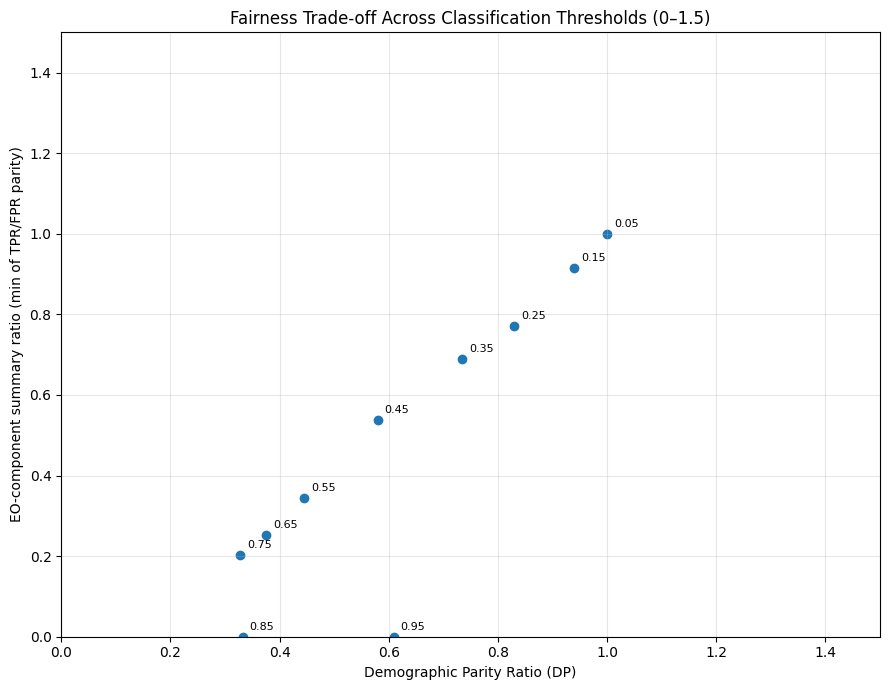

Points outside the 0–1.5 chart range (clipped in the required chart):


,Threshold,DP ratio,EO ratio,PP ratio


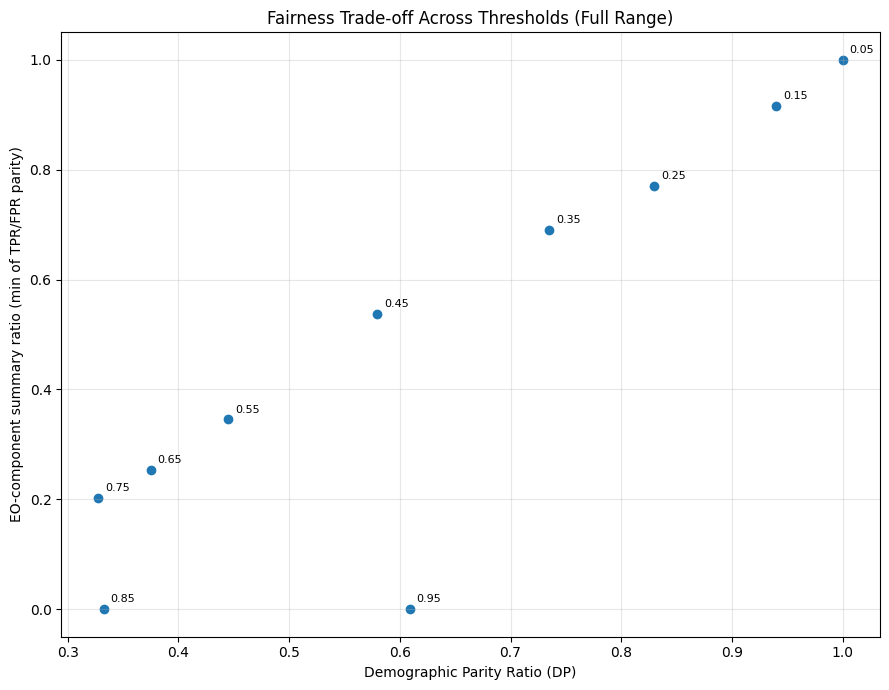

Fairness charts completed.


In [ ]:

# FINAL FAIRNESS TRADE-OFF CHARTS

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plot_df = fairness_table[
    ["Threshold", "DP ratio", "EO ratio", "PP ratio"]
].copy()

plot_df = plot_df.replace([np.inf, -np.inf], np.nan)

# Report rows where EO cannot be calculated
print("Threshold rows with missing DP/EO/PP values:")
display(plot_df[plot_df[["DP ratio", "EO ratio", "PP ratio"]].isna().any(axis=1)])

# Chart required by the assignment: both axes from 0 to 1.5
plt.figure(figsize=(9, 7))
valid = plot_df.dropna(subset=["DP ratio", "EO ratio"])

plt.scatter(valid["DP ratio"], valid["EO ratio"])

for _, row in valid.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP ratio"], row["EO ratio"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity Ratio (DP)")
plt.ylabel("EO-component summary ratio (min of TPR/FPR parity)")
plt.title("Fairness Trade-off Across Classification Thresholds (0–1.5)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print points that are outside the required chart limits
outside = valid[
    (valid["DP ratio"] > 1.5) | (valid["EO ratio"] > 1.5)
]
print("Points outside the 0–1.5 chart range (clipped in the required chart):")
display(outside)

# Additional full-range chart so all thresholds remain visible
if not valid.empty:
    plt.figure(figsize=(9, 7))
    plt.scatter(valid["DP ratio"], valid["EO ratio"])

    for _, row in valid.iterrows():
        plt.annotate(
            f'{row["Threshold"]:.2f}',
            (row["DP ratio"], row["EO ratio"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    plt.xlabel("Demographic Parity Ratio (DP)")
    plt.ylabel("EO-component summary ratio (min of TPR/FPR parity)")
    plt.title("Fairness Trade-off Across Thresholds (Full Range)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("Fairness charts completed.")


In [ ]:

# FINAL NUMERICAL FAIRNESS COMPARISON

fairness_summary = fairness_table[
    ["Threshold", "DP ratio", "EO ratio", "PP ratio"]
].copy()

display(fairness_summary.round(3))

# Compare thresholds with the lowest and highest observed DP ratio.
# This is descriptive; it does not automatically identify the fairest threshold.
valid_dp = fairness_summary.dropna(subset=["DP ratio"])

if len(valid_dp) >= 2:
    lowest_dp = valid_dp.loc[valid_dp["DP ratio"].idxmin()]
    highest_dp = valid_dp.loc[valid_dp["DP ratio"].idxmax()]

    print("\nLowest observed DP ratio:")
    print(lowest_dp.to_dict())

    print("\nHighest observed DP ratio:")
    print(highest_dp.to_dict())

    print("\nInterpretation:")
    print("A ratio closer to 1 is more balanced for that metric.")
    print("Compare DP, EO, and PP together; do not judge fairness using DP alone.")

# Show the threshold where each ratio is closest to 1
for metric in ["DP ratio", "EO ratio", "PP ratio"]:
    usable = fairness_summary.dropna(subset=[metric])
    if not usable.empty:
        best_row = usable.loc[(usable[metric] - 1).abs().idxmin()]
        print(
            f"Threshold closest to ideal for {metric}: "
            f"{best_row['Threshold']:.2f} "
            f"(ratio={best_row[metric]:.3f})"
        )


,Threshold,DP ratio,EO ratio,PP ratio
0,0.05,1.000,1.000,0.764
1,0.15,0.940,0.915,0.800
2,0.25,0.830,0.771,0.861
3,0.35,0.735,0.690,0.870
4,0.45,0.579,0.538,0.906
5,0.55,0.445,0.345,0.988
6,0.65,0.375,0.253,0.945
7,0.75,0.328,0.203,0.942
8,0.85,0.333,0.000,0.894
9,0.95,0.609,0.000,0.571



Lowest observed DP ratio:
{'Threshold': 0.75, 'DP ratio': 0.32790346907993967, 'EO ratio': 0.20314900153609833, 'PP ratio': 0.9415384615384614}

Highest observed DP ratio:
{'Threshold': 0.05, 'DP ratio': 1.0, 'EO ratio': 1.0, 'PP ratio': 0.7639328132686767}

Interpretation:
A ratio closer to 1 is more balanced for that metric.
Compare DP, EO, and PP together; do not judge fairness using DP alone.
Threshold closest to ideal for DP ratio: 0.05 (ratio=1.000)
Threshold closest to ideal for EO ratio: 0.05 (ratio=1.000)
Threshold closest to ideal for PP ratio: 0.55 (ratio=0.988)


## Interpretation: Numerical Fairness Comparison

The fairness comparison shows that the measured parity of the COMPAS model changes with the classification threshold. A symmetric parity ratio closer to 1 indicates greater parity for that metric. However, no single ratio provides a complete assessment of fairness.

Demographic parity (DP) compares the positive prediction rates across African-American and Caucasian groups. Equalized odds considers both true-positive rate (TPR) and false-positive rate (FPR) parity. In this notebook, the reported EO ratio is a conservative summary defined as the smaller of the TPR and FPR parity ratios; it is not a standalone standard Equalized Odds measure. Predictive parity (PP) compares positive predictive values.

At a threshold of 0.05, the DP ratio and EO-component summary ratio were both 1.000, while the PP ratio was 0.764. At a threshold of 0.55, the PP ratio was closest to 1, at 0.988, whereas the DP ratio was 0.445 and the EO-component summary ratio was 0.345. At a threshold of 0.75, the DP ratio was 0.328 and the EO-component summary ratio was 0.203, indicating lower parity for those measures. The EO-component summary ratio reached 0 at thresholds 0.85 and 0.95 because the FPR parity ratio was 0.

These results illustrate that improving parity for one metric does not necessarily improve it for others. A threshold of 0.05 should not automatically be considered the fairest overall, because parity ratios alone do not show the full impact of prediction errors or the consequences of classifying people as high risk. Threshold selection should consider DP, both TPR and FPR differences, PP, predictive performance, and the potential harms to affected individuals.
